# FX Technical Timing: Complete Research Record
## From indicator comparisons to time-currency analysis and economic filters

**Final consolidation, 22 October 2026. No additional rule selection or parameter tuning.**

This notebook documents the full research logic and reproduces its central calculations: the supplied exploratory notebook, fixed indicator and lookback comparisons, continuous PnL, variation across both currencies and time, currency-specific economic context, trade win rates and payoff ratios, and the economic entry/exit filters developed subsequently.

Every strategy runs independently on one FX pair. There is no cross-sectional currency ranking, portfolio allocation or rolling winner selection. A currency is not permanently assigned to momentum or mean reversion.

**Research status:** the main history has already been examined. Development/review splits are retrospective workflow boundaries, not newly untouched OOS. An earlier separate-source Federal Reserve H.10 extension is preserved in its own section and is not appended to the main-history curves.

### Reconstructed source and execution

Run `python run_research.py` from this directory, or run this notebook interactively. Source in `src/` rebuilds raw prices, 792 original accounts, 207 fixed baseline accounts, economic inputs and 288 filter accounts. Only NumPy, pandas and matplotlib are required; Excel is read with Python's standard library.

The original frozen engine and complete archive were not supplied. This implementation was reconstructed from the original notebook, documented rules and retained results; it is not byte-for-byte recovery. Original textual outputs are preserved in `reference/notebook_saved_outputs.json`. V3 technical gates, H.10 replay, V5 risk filters, state attribution, concentration and screening diagnostics are also recomputed. Screening assumptions are explicit because the original protocol is unavailable. New results go to `reproduced/` and `notebook_figures/`. The HTML supplies independent daily-path references.

**Accounting:** USD 100,000 per independent account; daily constant 1x signed foreign-currency exposure; zero transaction costs, carry, financing and cash interest. Open final positions are marked to market, not force-closed.

In [1]:
from pathlib import Path
import sys, json, hashlib, inspect, os
import numpy as np
import pandas as pd
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / 'reproduced' / '.matplotlib'))
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src/fx_research.py').is_file():
    if (ROOT / 'final_research/src/fx_research.py').is_file():
        ROOT = ROOT / 'final_research'
    else:
        raise FileNotFoundError('Open this notebook from the extracted complete research package.')
sys.path.insert(0, str(ROOT / 'src'))
import fx_research as fx
if 'display' not in globals():
    try:
        from IPython.display import display
    except ImportError:
        display = print
pd.set_option('display.max_columns', 14)
pd.set_option('display.width', 150)
pd.set_option('display.max_rows', 35)
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .22, 'font.size': 10})
DATA = fx.DATA
OUT = ROOT / 'reproduced'
FIGURES = ROOT / 'notebook_figures'
OUT.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
PAIR = 'CAD'                         # Any of EUR GBP AUD NZD JPY CHF CAD NOK SEK
RULE = 'BB_MR_20'                    # One fixed technical rule, not a selected winner

assert PAIR in fx.CURRENCIES
print('Ready. Main history: 2005-01-03 through 2026-05-29; previously examined.')

Ready. Main history: 2005-01-03 through 2026-05-29; previously examined.


## 1. The research logic and what changed

| Stage | Question | Implementation and retained evidence |
|---|---|---|
| Supplied exploration | How do indicators, lookbacks and holding conventions behave? | 20 rules, 9 currencies, 4 execution modes, plus 2 directional benchmarks. The earliest supplied snapshot available here already includes exits and multi-day holding. |
| Fixed-rule baseline | Can every rule be followed transparently without selecting recent winners? | All 20 rules retained independently; common 2005 start, earlier warmup, explicit trade ledger and corrected RSI center-crossing edge. The rolling-selection approach was rejected and is not part of the final strategy. |
| PnL and controlled comparisons | What produces the profits or losses? | Full daily paths, window and hypothesis comparisons, simple voting, controlled V3 variants, and an earlier H.10 extension. |
| Time x currency | When and where do the same rules work or fail? | Annual and calendar-period returns, position paths, event windows and currency-specific macro channels. Periods are descriptive, not trading inputs. |
| Risk and currency properties | Does stress mean the same thing for every currency and direction? | Daily VIX level/change, relative market yields, local FX volatility and commodity/USD context, with explicit information timing. |
| Trade quality | Are failed entries the problem, or is the loss tail too large? | Closed-trade win rate, average win/loss, payoff ratio, holding duration, entry cohorts and rejected-winner opportunity cost. |
| Economic filters | Can an economically justified conflict rule improve the original strategy? | V7 rate conflicts, three V8 entry hypotheses, a fixed OR, and one risk-exit addendum. All successes and failures retained. |

The supplied snapshot uses simple-return compounding and a two-close signal-to-first-return clock. Those are not new corrections. The material later changes are the RSI edge guard, the common evaluation start and explicit fixed-rule/reconciliation framework. Original and final numerical results are kept separate because their evaluation spans and RSI entry semantics differ.

## 2. Datasets, definitions and provenance

Two user-supplied workbooks support the main research. `FX_Technical_PIT_Dataset(6)(1).xlsx` provides the canonical daily price panel and monthly context. `FX_Features_Book(8).xlsx` adds the native daily risk, yield, commodity, FX-option and other economic series used for richer diagnosis.

The second workbook has the same hash as the upstream source recorded in the PIT workbook: it expands available variables, not the date range. It therefore does not create a new OOS sample. The latest supplied observation is 2026-05-29.

Prices used for signals and PnL are **USD per one unit of foreign currency**. Thus +1 means long foreign/short USD even when the market convention is USD/JPY or USD/CAD. The source `ret_1d` is a log return; the trading account independently computes simple close-to-close returns. Cross-sectional rank, bucket and `fwd_excess` labels are not used.

Feature dates are observation dates. Publication timestamps, actual close time/timezone, vendor series identity and revision vintages are incomplete. Prior-observation alignment reduces same-day look-ahead but does not certify strict real-time availability.

The supplied feature workbook also contains native-market-quote technical columns. Its stored RSI calculation is not substituted for the canonical-price Wilder RSI used here; all final trading indicators are independently rebuilt from the canonical spot series. Some inflation and commodity field identities or units remain unresolved and are archived rather than used in final filters.


In [2]:
manifest = json.loads((DATA / 'catalog/data_manifest.json').read_text())
inventory = pd.read_csv(DATA / 'catalog/dataset_inventory.csv')
dictionary = pd.read_csv(DATA / 'catalog/data_dictionary.csv')
display(inventory)
print('Canonical FX panel:', manifest['canonical_fx'])
raw_checks = fx.verify_raw_files()
display(raw_checks)
assert raw_checks.loc[raw_checks.available, 'sha256_matches'].all()
print('Missing original archival files are disclosed, not invented.')

Canonical FX panel: {'rows': 62010, 'currencies': ['AUD', 'CAD', 'CHF', 'EUR', 'GBP', 'JPY', 'NOK', 'NZD', 'SEK'], 'start': '2000-01-03', 'end': '2026-05-29', 'price_units': 'USD per foreign', 'source_daily_returns': 'log returns; independently recomputed simple returns drive PnL'}
Missing original archival files are disclosed, not invented.


,dataset,sheet,clean_file,rows,feature_columns,start,end,duplicate_dates
0,canonical_fx,PIT_Daily_Core,fx_spot_daily.csv,62010,4,2000-01-03,2026-05-29,NaN
1,original_context,PIT_Monthly,pit_monthly.csv,2853,64,2000-01-31,2026-05-29,NaN
2,separate_H10_extension,Federal Reserve H.10 historical pages,h10_official_daily.csv,7785,15,2023-06-26,2026-10-16,NaN
3,feature_workbook,1_FX_Spot,features_1_FX_Spot.csv,6890,11,2000-01-03,2026-05-29,0.0
4,feature_workbook,2_Rates,features_2_Rates.csv,6890,22,2000-01-03,2026-05-29,0.0
5,feature_workbook,3_Growth,features_3_Growth.csv,316,12,2000-01-31,2026-04-30,0.0
6,feature_workbook,4_Inflation,features_4_Inflation.csv,316,10,2000-01-31,2026-04-30,0.0
7,feature_workbook,5_Equities,features_5_Equities.csv,6871,10,2000-01-03,2026-05-29,0.0
8,feature_workbook,6_Vol_Credit,features_6_Vol_Credit.csv,6828,5,2000-01-03,2026-05-29,0.0
9,feature_workbook,7_FX_Options,features_7_FX_Options.csv,6888,14,2000-01-03,2026-05-29,0.0


,manifest_path,actual_path,available,sha256_matches
0,data/raw/FX_Features_Book(8).xlsx,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\raw\FX_Features_Book.xlsx,True,True
1,data/raw/FX_Technical_Complete_Research.ipynb,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\raw\FX_Technical_Complete_Research.ipynb,True,True
2,data/raw/FX_Technical_PIT_Dataset(6)(1).xlsx,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\raw\FX_Technical_PIT_Dataset(6)(1).xlsx,True,True
3,data/raw/rejected_rolling_selection_notebook_snapshot.json,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\raw\rejected_rolling_selection_notebook_snapshot.json,False,False


In [3]:
# Rebuild the canonical price panel from the original Excel, not from prior results.
prices, original_monthend_indicators = fx.canonical_prices_from_raw()
coverage = prices.groupby('pair').agg(observations=('date','size'), first=('date','min'), last=('date','max'),
                                    missing_prices=('price_USD_per_foreign',lambda x: x.isna().sum()))
display(coverage)
assert len(prices)==62010 and coverage.observations.eq(6890).all()
assert not prices.duplicated(['pair','date']).any()
assert prices.price_USD_per_foreign.gt(0).all()
log_errors=[]
for pair,g in prices.groupby('pair'):
    g=g.sort_values('date')
    recomputed=np.log(g.price_USD_per_foreign).diff()
    log_errors.append({'pair':pair,'max_abs_source_log_return_error':float(np.nanmax(np.abs(recomputed-g.source_log_return_1d)))})
display(pd.DataFrame(log_errors))
assert max(x['max_abs_source_log_return_error'] for x in log_errors)<1e-9

,observations,first,last,missing_prices
pair,,,,
AUD,6890,2000-01-03,2026-05-29,0
CAD,6890,2000-01-03,2026-05-29,0
CHF,6890,2000-01-03,2026-05-29,0
EUR,6890,2000-01-03,2026-05-29,0
GBP,6890,2000-01-03,2026-05-29,0
JPY,6890,2000-01-03,2026-05-29,0
NOK,6890,2000-01-03,2026-05-29,0
NZD,6890,2000-01-03,2026-05-29,0
SEK,6890,2000-01-03,2026-05-29,0


,pair,max_abs_source_log_return_error
0,AUD,5.551115e-17
1,CAD,5.551115e-17
2,CHF,5.551115e-17
3,EUR,5.551115e-17
4,GBP,5.551115e-17
5,JPY,0.000000e+00
6,NOK,4.440892e-16
7,NZD,1.110223e-16
8,SEK,2.220446e-16


## 3. Reproduce the supplied exploratory version

This stage answers the initial, simple question: how do the same technical signals behave under different execution/holding conventions? Its full 2000-2026 sample and original RSI edge behavior are preserved. It is a historical exploration, not a competition used to choose a later trading rule.

The four modes are daily continuous, daily with Friday flattening, weekly flat, and fixed five-return-interval holding. Daily continuous means a position is held until the rule changes; it does not mean each trade lasts one day. The archived original notebook is retained for exact provenance. We rerun its indicator, execution and performance definitions here; the archived raw notebook retains its full original macro and bootstrap exploration.

In [4]:
original_metrics = fx.original_exploration(prices)
original_checks = fx.verify_original_metrics(original_metrics)
display(original_checks)
assert original_checks['pass'].all(), original_checks.to_string(index=False)
original_reference = pd.read_csv(DATA / 'clean/original_exploration_metrics_rebuilt.csv')
join = original_metrics.merge(original_reference, on=['pair','strategy','mode'], suffixes=('_new','_reference'))
assert len(original_metrics)==792 and len(join)==792
assert np.allclose(join.total_return_pct_new, join.total_return_pct_reference, atol=1e-7, rtol=1e-10)
original_metrics.to_csv(OUT/'original_snapshot_792_accounts.csv',index=False)
original_technical=original_metrics[~original_metrics.benchmark]
mode_summary=original_technical.groupby('mode').agg(accounts=('strategy','size'),
    positive_accounts=('total_return_pct',lambda x:int((x>0).sum())),
    median_return_pct=('total_return_pct','median'))
display(mode_summary)
display(original_technical[original_technical.pair.eq(PAIR)][['pair','strategy','mode','total_return_pct','max_drawdown_pct','active_pct']].head(24))

,metric,accounts,max_abs_error,pass
0,account_coverage,792,0.000000e+00,True
1,active_day_win_rate_pct,792,7.105427e-15,True
2,active_pct,792,1.421085e-14,True
3,annualized_return_pct,792,2.220446e-14,True
4,annualized_vol_pct,792,1.776357e-15,True
5,average_daily_bp,792,2.220446e-16,True
6,benchmark,792,0.000000e+00,True
7,family,792,0.000000e+00,True
8,hypothesis,792,0.000000e+00,True
9,long_foreign_pct,792,7.105427e-15,True


,accounts,positive_accounts,median_return_pct
mode,,,
Daily Continuous,180,64,-9.317170
Daily Weekflat,180,95,1.245579
Fixed 5D,180,61,-9.544907
Weekly Flat,180,88,-1.198939


,pair,strategy,mode,total_return_pct,max_drawdown_pct,active_pct
528,CAD,RSI_MR_7,Daily Continuous,31.150607,-17.956084,32.699565
529,CAD,RSI_MR_7,Daily Weekflat,2.473850,-23.470865,26.168360
530,CAD,RSI_MR_7,Weekly Flat,-3.294592,-25.711927,26.473149
531,CAD,RSI_MR_7,Fixed 5D,7.436890,-24.948760,32.264151
532,CAD,RSI_MR_14,Daily Continuous,-10.782814,-21.847890,23.323657
533,CAD,RSI_MR_14,Daily Weekflat,-17.993275,-24.890253,18.635704
534,CAD,RSI_MR_14,Weekly Flat,-8.472308,-21.370006,18.809869
535,CAD,RSI_MR_14,Fixed 5D,-27.696337,-30.581723,23.294630
536,CAD,RSI_MR_20,Daily Continuous,-6.979540,-22.495643,14.716981
537,CAD,RSI_MR_20,Daily Weekflat,-19.105433,-24.060687,11.741655


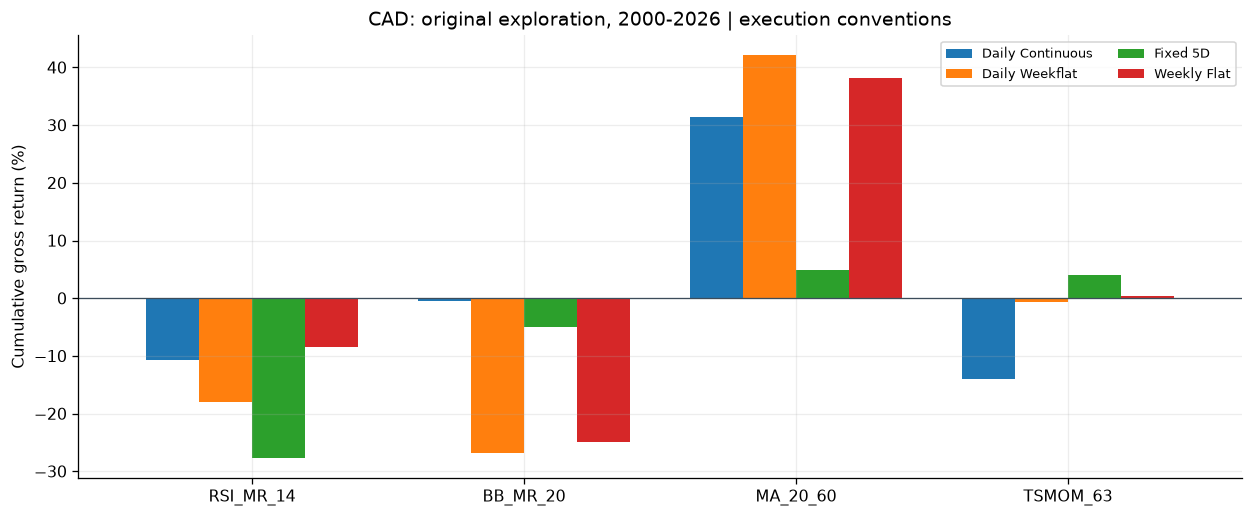

In [5]:
selected_original=original_technical[original_technical.pair.eq(PAIR) & original_technical.strategy.isin(fx.CORE_RULES)]
pivot=selected_original.pivot(index='strategy',columns='mode',values='total_return_pct').reindex(fx.CORE_RULES)
ax=pivot.plot.bar(figsize=(11,4.6),width=.78)
ax.axhline(0,color='#3c4c5a',lw=.8);ax.set_ylabel('Cumulative gross return (%)')
ax.set_title(f'{PAIR}: original exploration, 2000-2026 | execution conventions')
ax.set_xlabel('');plt.xticks(rotation=0);ax.legend(ncol=2,fontsize=8)
plt.tight_layout();plt.savefig(FIGURES/'01_original_execution_modes.png');plt.show()

## 4. Fixed technical rules and transparent entry-hold-exit logic

All 20 rules remain available. RSI uses windows 7, 14 and 20; moving averages use 10/30 and 20/60; Bollinger and Donchian use 10 and 20; time-series momentum uses 21 and 63; MACD is 12/26/9. RSI and Bollinger compare momentum/breakout with mean reversion explicitly.

- **RSI mean reversion:** enter long only when RSI crosses back above 30 while still below 50; enter short only when crossing back below 70 while still above 50; exit at the 50 center. This prevents opening after the intended exit level has already been passed.
- **Bollinger mean reversion:** enter opposite a two-standard-deviation excursion and exit on return to the center. Breakout uses the opposite direction and exits through the center in the adverse direction.
- **Trend/momentum rules:** hold the indicated direction until the rule turns flat or reverses. Donchian thresholds use the previous window, excluding today's close.
- **Voting:** equal voting uses the sign of four votes; ties are flat. Strength voting uses deterministic price-derived weights and a fixed 0.2 cutoff. These are not fitted probabilities or historical-performance weights.

Let $s_t$ be the target known after close $t$. The executed position is $e_{t+1}=s_t$, and the position earning the return ending at $t+2$ is $h_{t+2}=e_{t+1}$. The daily account is

$$r_t^{strategy}=h_t\left(P_t/P_{t-1}-1\right),\qquad PnL_t=100000\left[\prod_{u\le t}(1+r_u^{strategy})-1\right].$$

The 2000-2004 observations warm up indicators and state machines. All final fixed accounts start from cash at the first permitted 2005 execution. A final open position is marked to market without an artificial final liquidation.

In [6]:
rule_specifications=pd.DataFrame([{'strategy':k,'indicator':v[0],'hypothesis':v[1],'entry_hold_exit_rule':v[2]}
                                   for k,v in fx.RULES.items() if k in fx.STRATEGIES])
display(rule_specifications)
# The exact executable logic is visible, not only a prose rule description.
print(inspect.getsource(fx.event_osc_reversion))
print(inspect.getsource(fx.fixed_execute))

def event_osc_reversion(values, low=30.0, high=70.0, center=50.0):
    """Re-enter before the exit level, preserving state across missing values."""
    signals = np.zeros(len(values), np.int8)
    position = 0
    for index in range(1, len(values)):
        value, previous = values[index], values[index - 1]
        if not np.isfinite(value) or not np.isfinite(previous):
            signals[index] = position
            continue
        if position == 1 and value >= center:
            position = 0
        elif position == -1 and value <= center:
            position = 0
        if previous < low <= value < center:
            position = 1
        elif previous > high >= value > center:
            position = -1
        signals[index] = position
    return signals

def fixed_execute(prices, targets, cost_bp=0.0, capital=100000.0):
    """Signal t executes at close t+1, earning its first return at t+2.

    Exposure is a daily 1x target. Direction changes incur the optional one-way
    

,strategy,indicator,hypothesis,entry_hold_exit_rule
0,RSI_MR_7,RSI,Mean reversion,7d Wilder RSI re-enters 30..50 / 50..70; exit at 50
1,RSI_MR_14,RSI,Mean reversion,14d Wilder RSI re-enters 30..50 / 50..70; exit at 50
2,RSI_MR_20,RSI,Mean reversion,20d Wilder RSI re-enters 30..50 / 50..70; exit at 50
3,RSI_MOM_7,RSI,Momentum,"7d RSI >60 long FX, <40 short FX, otherwise flat"
4,RSI_MOM_14,RSI,Momentum,"14d RSI >60 long FX, <40 short FX, otherwise flat"
5,RSI_MOM_20,RSI,Momentum,"20d RSI >60 long FX, <40 short FX, otherwise flat"
6,MA_10_30,Moving average,Trend following,Sign of SMA10 minus SMA30
7,MA_20_60,Moving average,Trend following,Sign of SMA20 minus SMA60
8,BB_MR_10,Bollinger,Mean reversion,"10d sample-SD z-score: fade +/-2, exit at zero"
9,BB_MR_20,Bollinger,Mean reversion,"20d sample-SD z-score: fade +/-2, exit at zero"


In [7]:
baseline_metrics, baseline_trades, baseline_runs, price_dates, indicators = fx.reconstruct_fixed_baselines(prices)
baseline_checks, compared_daily_rows = fx.verify_baselines(baseline_metrics,baseline_runs,price_dates)
display(baseline_checks)
assert baseline_checks['pass'].all(), baseline_checks.to_string(index=False)
print(f'Reconciled {compared_daily_rows:,} daily records and all 207 accounts (180 technical + 27 benchmarks/cash).')
baseline_metrics.to_csv(OUT/'fixed_baseline_metrics.csv',index=False)
baseline_trades.to_csv(OUT/'fixed_baseline_trade_ledger.csv.gz',index=False)
tech=baseline_metrics[baseline_metrics.technical].copy()
display(tech[tech.pair.eq(PAIR)][['strategy','total_return_pct','cagr_calendar_pct','max_drawdown_pct','win_rate','payoff_ratio','eligible_closed_n']])

Reconciled 1,156,095 daily records and all 207 accounts (180 technical + 27 benchmarks/cash).


,check,expected_rows,compared_rows,max_abs_error,mismatch_count,absolute_tolerance,pass,reference_source
0,baseline metrics: exact key coverage,207,207,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
1,baseline metrics: indicator,207,207,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
2,baseline metrics: hypothesis,207,207,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
3,baseline metrics: technical,207,207,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
4,baseline metrics: start_date,207,207,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
5,baseline metrics: end_date,207,207,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
6,baseline metrics: observations,207,207,0.000000e+00,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
7,baseline metrics: total_return_pct,207,207,7.105427e-15,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
8,baseline metrics: cagr_calendar_pct,207,207,8.881784e-16,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv
9,baseline metrics: sharpe_252,207,207,9.714451e-17,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\fixed_baseline_metrics_rebuilt.csv


,strategy,total_return_pct,cagr_calendar_pct,max_drawdown_pct,win_rate,payoff_ratio,eligible_closed_n
138,RSI_MR_7,40.079129,1.586866,-17.704126,0.658333,0.728511,240
139,RSI_MR_14,-7.011945,-0.339025,-21.847890,0.666667,0.438293,66
140,RSI_MR_20,2.055633,0.095097,-15.875778,0.653846,0.592592,26
141,RSI_MOM_7,-29.877088,-1.644277,-33.097029,0.429803,1.162348,812
142,RSI_MOM_14,-17.087741,-0.871525,-25.795381,0.428571,1.206056,476
143,RSI_MOM_20,-5.613015,-0.269484,-20.255506,0.430723,1.282149,332
144,MA_10_30,-19.725414,-1.021118,-41.668057,0.337719,1.777090,228
145,MA_20_60,5.169033,0.235706,-28.765123,0.351351,2.028121,111
146,BB_MR_10,31.446406,1.285465,-20.877359,0.618834,0.806707,223
147,BB_MR_20,5.715812,0.259989,-28.010972,0.648649,0.582767,185


## 5. PnL comparisons: hypotheses, windows and simple combinations

The comparisons below retain all specified windows. They are not rolling selections and do not choose a permanent winning strategy for a currency. A higher full-history endpoint can coexist with long losing subperiods. The same 100,000 USD capital convention applies to every line.

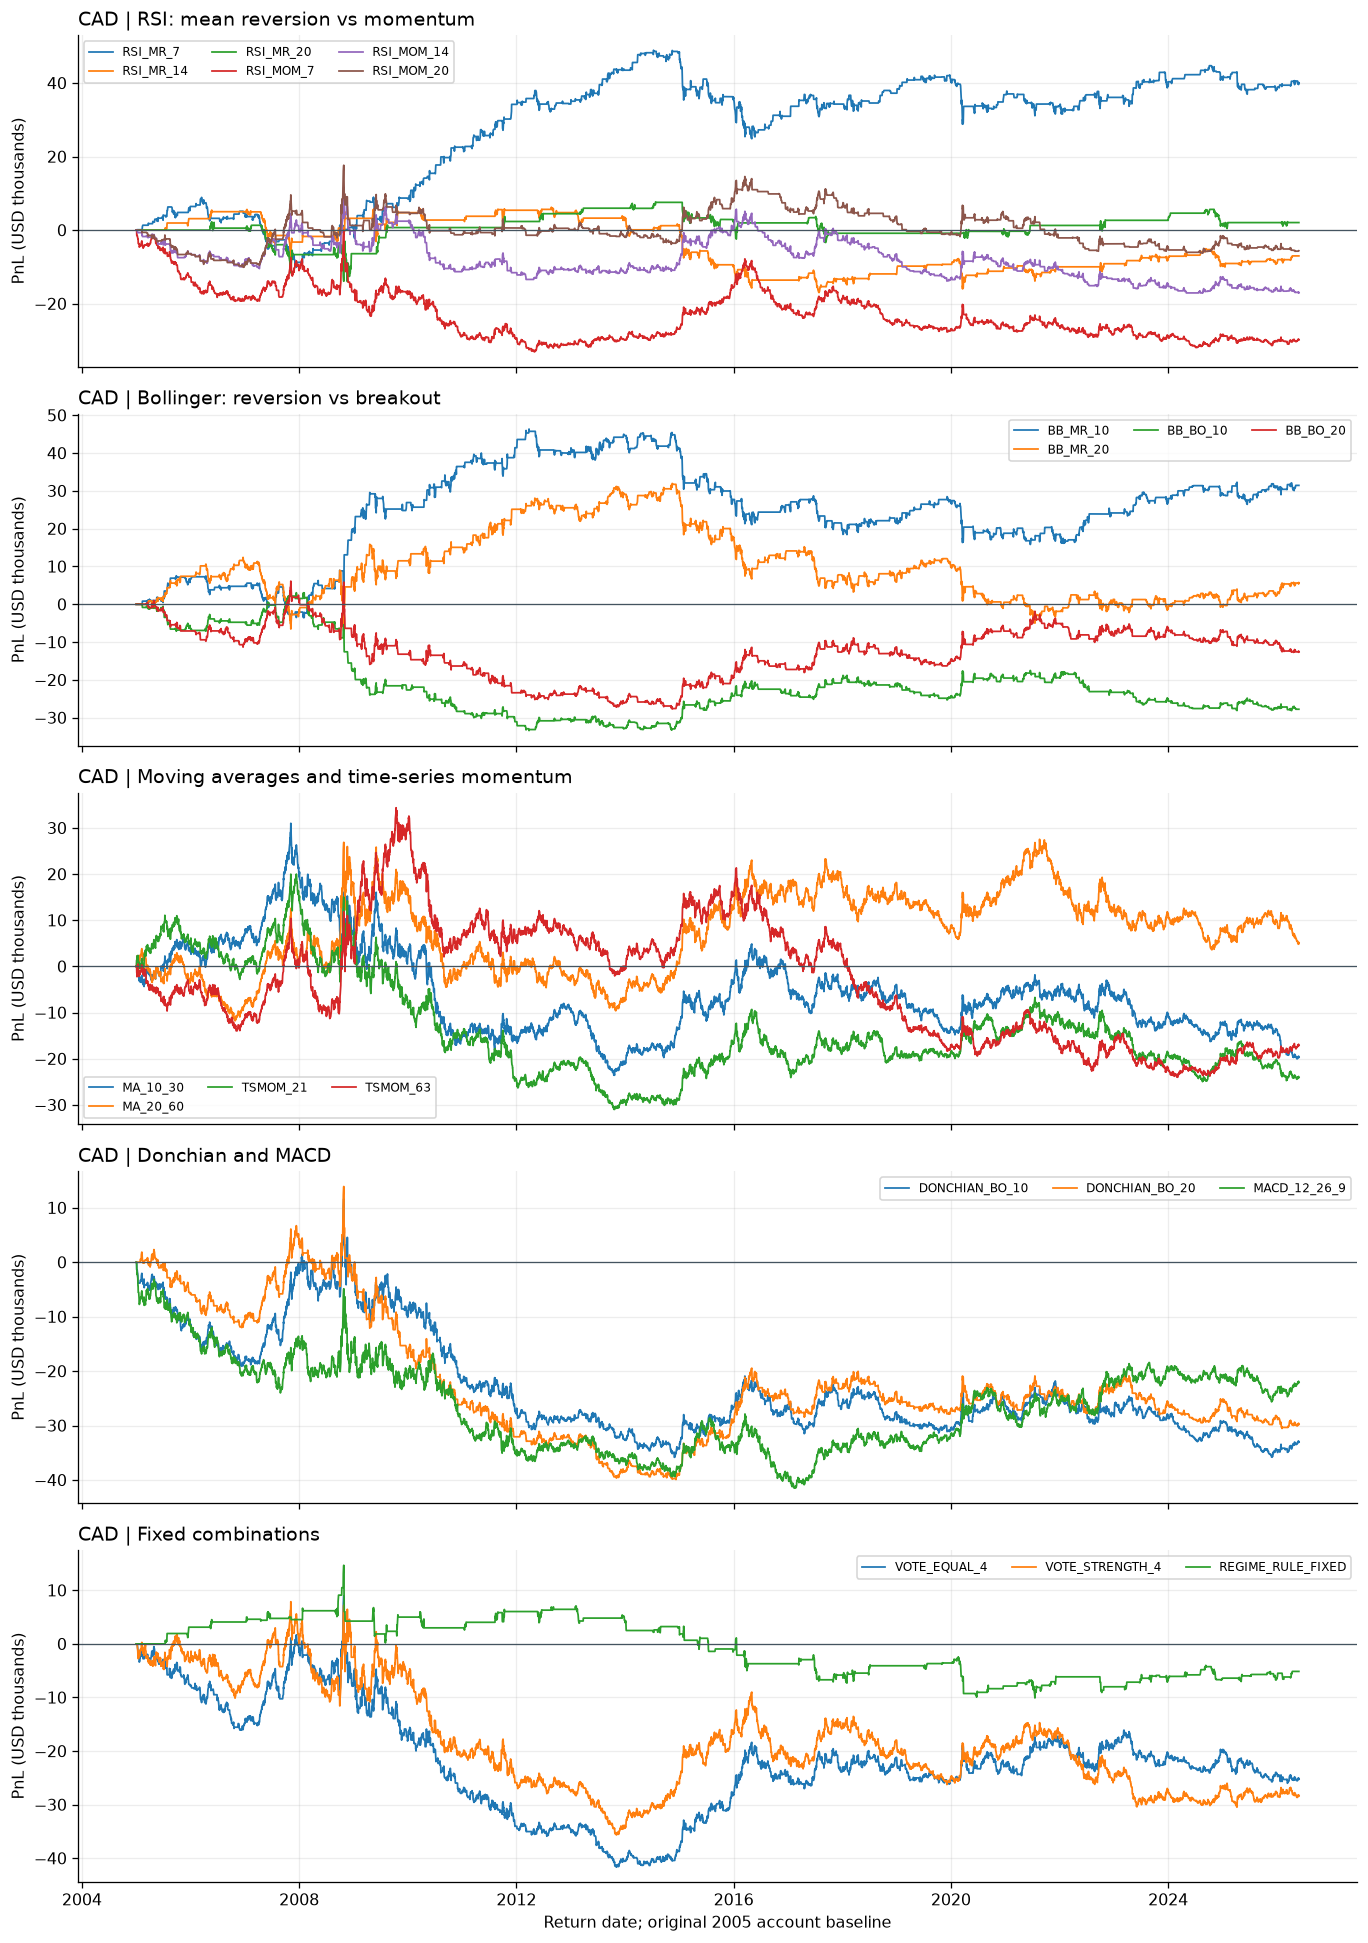

In [8]:
families=[('RSI: mean reversion vs momentum',['RSI_MR_7','RSI_MR_14','RSI_MR_20','RSI_MOM_7','RSI_MOM_14','RSI_MOM_20']),
 ('Bollinger: reversion vs breakout',['BB_MR_10','BB_MR_20','BB_BO_10','BB_BO_20']),
 ('Moving averages and time-series momentum',['MA_10_30','MA_20_60','TSMOM_21','TSMOM_63']),
 ('Donchian and MACD',['DONCHIAN_BO_10','DONCHIAN_BO_20','MACD_12_26_9']),
 ('Fixed combinations',['VOTE_EQUAL_4','VOTE_STRENGTH_4','REGIME_RULE_FIXED'])]
fig,axes=plt.subplots(5,1,figsize=(12,17),sharex=True)
dates=price_dates[PAIR];mask=dates>='2004-12-31'
for ax,(title,names) in zip(axes,families):
    for name in names:ax.plot(dates[mask],100*(baseline_runs[(PAIR,name)]['equity'][mask]-1),label=name,lw=1.1)
    ax.axhline(0,color='#445460',lw=.8);ax.set_title(f'{PAIR} | {title}',loc='left')
    ax.set_ylabel('PnL (USD thousands)');ax.legend(ncol=3,fontsize=7.5)
axes[-1].set_xlabel('Return date; original 2005 account baseline')
plt.tight_layout();plt.savefig(FIGURES/'02_all_indicator_families_selected_pair.png');plt.show()

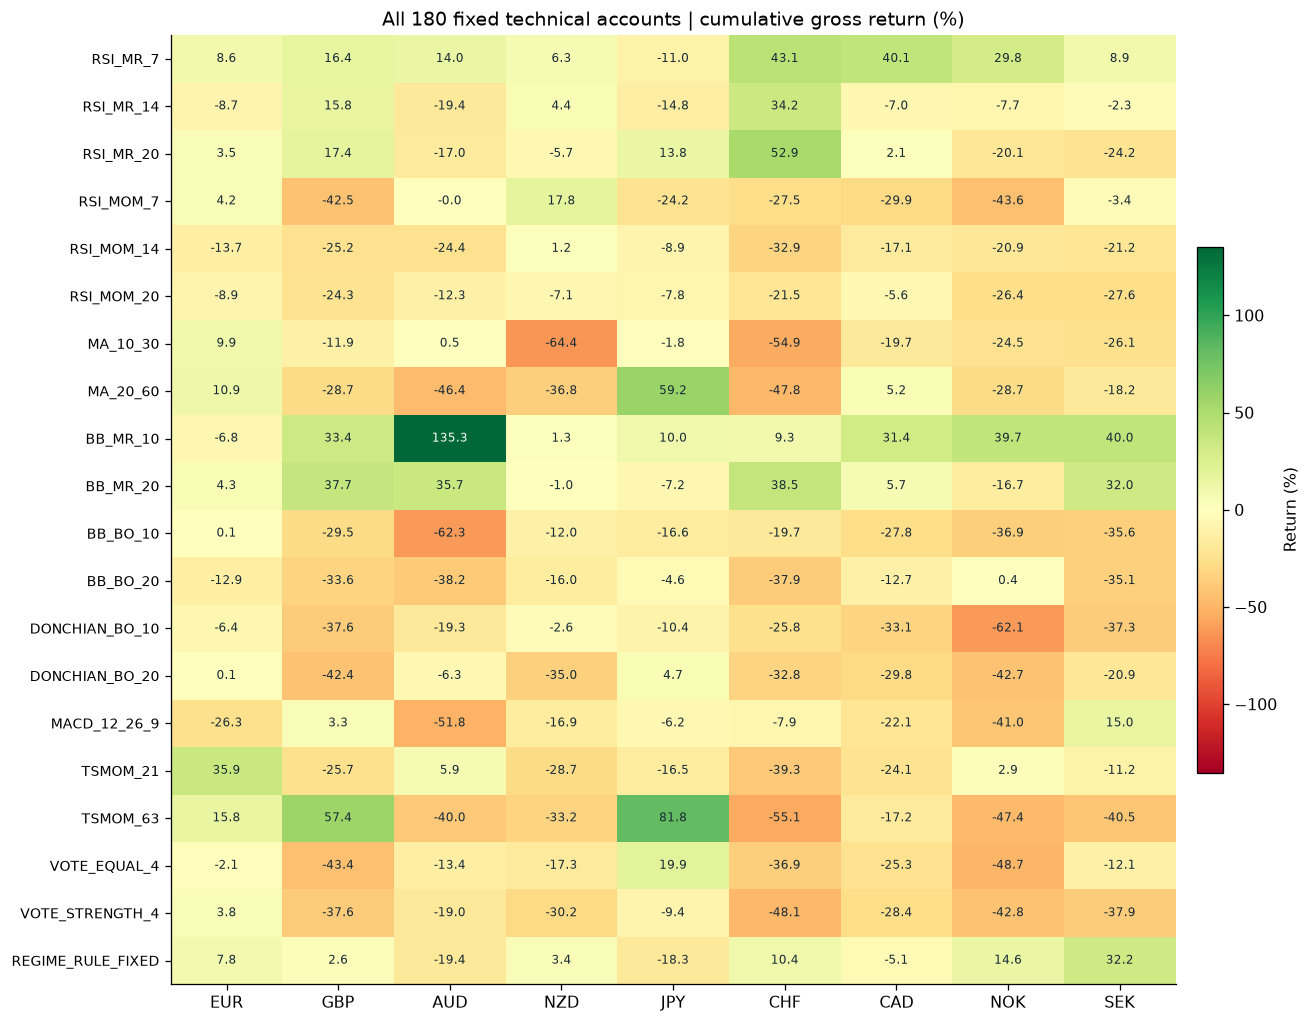

In [9]:
# Every currency and every technical rule remains visible in the endpoint comparison.
grid=tech.pivot(index='strategy',columns='pair',values='total_return_pct').reindex(index=fx.STRATEGIES,columns=fx.CURRENCIES)
fig,ax=plt.subplots(figsize=(11.5,9.0));limit=max(abs(grid.min().min()),abs(grid.max().max()))
im=ax.imshow(grid.to_numpy(),cmap='RdYlGn',vmin=-limit,vmax=limit,aspect='auto')
ax.set_xticks(range(9),fx.CURRENCIES);ax.set_yticks(range(20),fx.STRATEGIES,fontsize=8.5)
ax.grid(False)
for i in range(20):
    for j in range(9):ax.text(j,i,f'{grid.iloc[i,j]:.1f}',ha='center',va='center',fontsize=7.5,color='white' if abs(grid.iloc[i,j])>.65*limit else '#172a36')
ax.set_title('All 180 fixed technical accounts | cumulative gross return (%)')
fig.colorbar(im,ax=ax,label='Return (%)',fraction=.025,pad=.02)
plt.tight_layout();plt.savefig(FIGURES/'03_all_rules_currency_heatmap.png');plt.show()

In [10]:
window_comparisons, voting = fx.window_diagnostics(baseline_runs, price_dates)
display(window_comparisons[window_comparisons.pair.eq(PAIR)][['family','shorter_window_rule','longer_window_rule',
 'shorter_full_return_pct','longer_full_return_pct','position_disagreement_pct','window_order_changes_across_periods']])
display(voting[['pair','equal_full_return_pct','strength_full_return_pct','strength_minus_equal_percentage_points',
 'equal_positive_periods','strength_positive_periods']])
print('Window ordering changes across historical periods in',int(window_comparisons.window_order_changes_across_periods.sum()),'of',len(window_comparisons),'pairwise comparisons.')

Window ordering changes across historical periods in 69 of 99 pairwise comparisons.


,family,shorter_window_rule,longer_window_rule,shorter_full_return_pct,longer_full_return_pct,position_disagreement_pct,window_order_changes_across_periods
66,RSI_MR,RSI_MR_7,RSI_MR_14,40.079129,-7.011945,29.471799,True
67,RSI_MR,RSI_MR_7,RSI_MR_20,40.079129,2.055633,34.127126,True
68,RSI_MR,RSI_MR_14,RSI_MR_20,-7.011945,2.055633,18.012534,False
69,RSI_MOM,RSI_MOM_7,RSI_MOM_14,-29.877088,-17.087741,23.133393,True
70,RSI_MOM,RSI_MOM_7,RSI_MOM_20,-29.877088,-5.613015,34.521038,True
71,RSI_MOM,RSI_MOM_14,RSI_MOM_20,-17.087741,-5.613015,12.121755,True
72,MA,MA_10_30,MA_20_60,-19.725414,5.169033,27.233662,False
73,BB_MR,BB_MR_10,BB_MR_20,31.446406,5.715812,36.687556,False
74,BB_BO,BB_BO_10,BB_BO_20,-27.762348,-12.660773,36.687556,False
75,DONCHIAN,DONCHIAN_BO_10,DONCHIAN_BO_20,-33.072269,-29.817683,33.124440,True


,pair,equal_full_return_pct,strength_full_return_pct,strength_minus_equal_percentage_points,equal_positive_periods,strength_positive_periods
0,EUR,-2.094565,3.847641,5.942206,1,1
1,GBP,-43.425522,-37.584880,5.840642,0,0
2,AUD,-13.382542,-18.972777,-5.590234,1,1
3,NZD,-17.307385,-30.154063,-12.846678,0,0
4,JPY,19.933780,-9.432578,-29.366359,1,1
5,CHF,-36.886458,-48.066363,-11.179905,1,1
6,CAD,-25.274746,-28.412836,-3.138090,1,1
7,NOK,-48.711816,-42.799611,5.912206,0,0
8,SEK,-12.117106,-37.882655,-25.765548,2,0


### 5.1 Controlled V3 variants and the earlier external-data replay

The earlier research also tested a small set of controlled variants and a separate-source Federal Reserve H.10 extension. These records are retained to show the actual research path, including unsuccessful ideas. They are not additional filters silently folded into V8.

The H.10 extension begins in June 2026, after the main workbook ends, and was previously evaluated with frozen technical rules. It is a separate-source, short historical extension, with source-bridge and coverage issues explicitly audited. It has now been seen, so it is not an untouched test set for the later V7/V8 filter design. Macro inputs needed for those final filters were not extended in parallel. No filtered OOS result is fabricated from this partial extension.

Official source: [Federal Reserve H.10 foreign exchange rates](https://www.federalreserve.gov/releases/h10/).

In [11]:
v3_result = fx.reconstruct_v3(prices)
v3_checks = fx.verify_legacy(v3_result, 'technical')
display(v3_checks.groupby('pass').size().rename('checks'))
controlled = v3_result['comparisons']
display(controlled[controlled.pair.eq(PAIR)][['pair', 'strategy', 'base_strategy', 'stage', 'start_date', 'end_date', 'total_return_pct', 'pnl_change_usd', 'drawdown_change_pp']])
v3_result['metrics'].to_csv(OUT / 'v3_account_metrics.csv', index=False)
v3_result['trades'].to_csv(OUT / 'v3_trade_ledger.csv.gz', index=False)
v3_checks.to_csv(OUT / 'v3_reconciliation.csv', index=False)
h10_result = fx.reconstruct_h10()
h10_checks = fx.verify_legacy(h10_result, 'h10')
external = h10_result['metrics']
display(h10_result['coverage'])
display(external[external.pair.eq(PAIR) & external.strategy.isin(fx.CORE_RULES)][['pair', 'strategy', 'start_date', 'end_date', 'observations', 'total_return_pct', 'max_drawdown_pct', 'closed_trades', 'open_trades_at_end']])
external.to_csv(OUT / 'h10_account_metrics.csv', index=False)
h10_result['coverage'].to_csv(OUT / 'h10_coverage.csv', index=False)
h10_result['trades'].to_csv(OUT / 'h10_trade_ledger.csv.gz', index=False)
h10_checks.to_csv(OUT / 'h10_reconciliation.csv', index=False)

pass
True    703
Name: checks, dtype: int64

,pair,strategy,base_strategy,stage,start_date,end_date,total_return_pct,pnl_change_usd,drawdown_change_pp
72,CAD,BB10_RANGE_GATE,BB_MR_10,D,2005-01-03,2014-12-31,40.072146,-1122.008994,3.477565
73,CAD,BB20_RANGE_GATE,BB_MR_20,D,2005-01-03,2014-12-31,49.327378,19588.254719,10.364372
74,CAD,MOM63_TREND_GATE,TSMOM_63,D,2005-01-03,2014-12-31,-2.934168,-8756.607344,19.570860
75,CAD,MOM_MA_CONFIRM,TSMOM_63,D,2005-01-03,2014-12-31,4.175929,-1646.510227,1.754246
76,CAD,BB10_RANGE_GATE,BB_MR_10,V,2015-01-01,2019-12-31,-2.319779,7893.910152,5.049486
77,CAD,BB20_RANGE_GATE,BB_MR_20,V,2015-01-01,2019-12-31,-9.504994,5923.144015,6.267684
78,CAD,MOM63_TREND_GATE,TSMOM_63,V,2015-01-01,2019-12-31,-2.315538,19216.532182,28.798467
79,CAD,MOM_MA_CONFIRM,TSMOM_63,V,2015-01-01,2019-12-31,-7.633808,13898.262133,10.783797
80,CAD,BB10_RANGE_GATE,BB_MR_10,T,2020-01-01,2026-05-29,4.735518,1025.143885,2.358563
81,CAD,BB20_RANGE_GATE,BB_MR_20,T,2020-01-01,2026-05-29,-5.304654,-1592.075367,3.215007


,pair,warmup_start,pre_sample_valid_observations,sample_first,sample_last,sample_valid_quotes,sample_calendar_weekdays,sample_ND_dates,earlier_warmup_all_targets_identical,source_url,calendar_missing_quote_dates
0,EUR,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_eu.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
1,GBP,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_uk.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
2,AUD,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_al.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
3,NZD,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_nz.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
4,JPY,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_ja.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
5,CHF,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_sz.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
6,CAD,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_ca.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
7,NOK,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_no.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12
8,SEK,2024-01-02,604,2026-06-01,2026-10-16,96,100,4,True,https://www.federalreserve.gov/releases/h10/hist/dat00_sd.htm,2026-06-19;2026-07-03;2026-09-07;2026-10-12


,pair,strategy,start_date,end_date,observations,total_return_pct,max_drawdown_pct,closed_trades,open_trades_at_end
139,CAD,RSI_MR_14,2026-06-01,2026-10-16,96,1.100100,-1.868371,2,1.0
145,CAD,MA_20_60,2026-06-01,2026-10-16,96,-3.920228,-5.903112,3,1.0
147,CAD,BB_MR_20,2026-06-01,2026-10-16,96,-4.623425,-5.501126,2,1.0
154,CAD,TSMOM_63,2026-06-01,2026-10-16,96,-4.298847,-6.972011,4,1.0


## 6. Time and currency are joint dimensions

We now ask a more useful question than which currency has the best full-sample rule: how does the same strategy change across historical environments, and how does the same environment affect different currencies and trade directions?

Calendar blocks and event windows are explanatory partitions. They do not switch strategies. Period returns compound the actual daily returns in the period while inheriting the original positions. They are not sums of closed trades, and period return differences cannot be added to recover the full-history difference.

Four fixed representatives make detailed economic analysis readable: TSMOM63 and MA20/60 for momentum/trend, BB20 and RSI14 for mean reversion. All 20 original rules remain in the broader comparison. The four representatives are not an ex-post portfolio.

period,2005-2009,2010-2014,2015-2019,2020-2024,2025-May2026
strategy,,,,,
BB_MR_20,11.494986,16.363191,-15.355301,-9.254912,6.083073
MA_20_60,16.637938,-13.659390,8.061668,-0.872954,-2.507972
RSI_MR_14,4.741483,-3.299457,-10.455674,-0.177447,2.710013
TSMOM_63,29.633722,-18.368124,-21.599651,-3.708144,3.701021


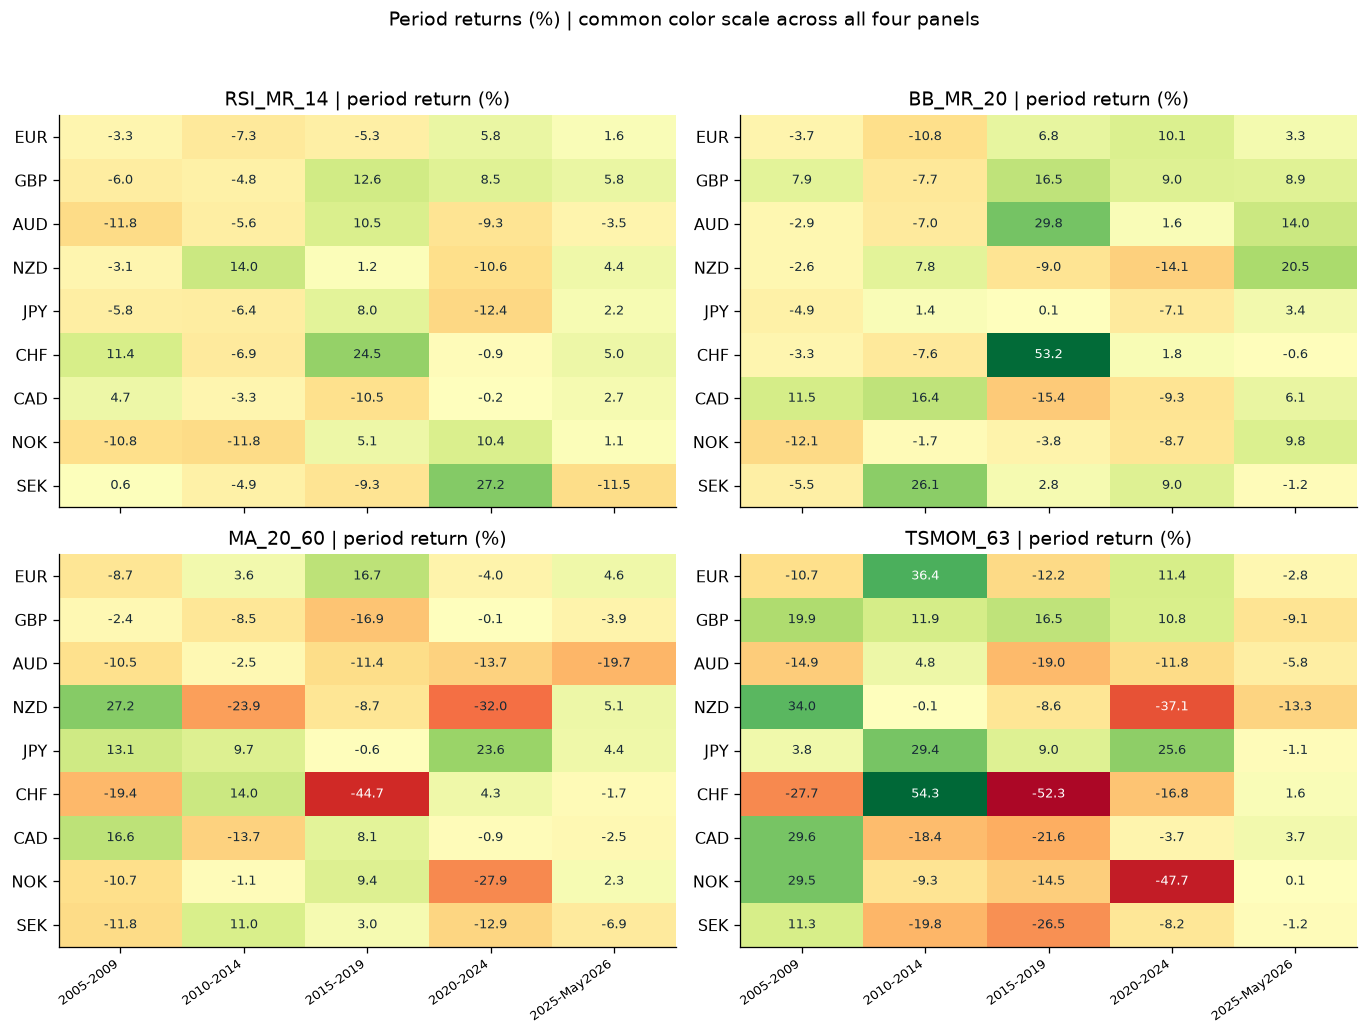

In [12]:
annual=fx.annual_table(baseline_runs,price_dates)
periods=fx.period_table(baseline_runs,price_dates)
annual.to_csv(OUT/'annual_returns_all20.csv',index=False)
periods.to_csv(OUT/'calendar_periods_core4.csv',index=False)
display(periods[periods.pair.eq(PAIR)].pivot(index='strategy',columns='period',values='return_pct'))
fig,axes=plt.subplots(2,2,figsize=(12,9),sharex=True)
for ax,rule in zip(axes.flat,fx.CORE_RULES):
    z=periods[periods.strategy.eq(rule)].pivot(index='pair',columns='period',values='return_pct').reindex(fx.CURRENCIES)
    vmax=max(15,float(np.abs(periods.return_pct.to_numpy()).max()))
    ax.imshow(z.to_numpy(),cmap='RdYlGn',vmin=-vmax,vmax=vmax,aspect='auto')
    ax.set_yticks(range(9),fx.CURRENCIES);ax.set_xticks(range(5),z.columns,rotation=35,ha='right',fontsize=8)
    for i in range(9):
        for j in range(5):ax.text(j,i,f'{z.iloc[i,j]:.1f}',ha='center',va='center',fontsize=8,color='white' if abs(z.iloc[i,j])>.65*vmax else '#172a36')
    ax.grid(False);ax.set_title(rule+' | period return (%)')
fig.suptitle('Period returns (%) | common color scale across all four panels',y=.995)
plt.tight_layout(rect=[0,0,1,.97]);plt.savefig(FIGURES/'04_time_currency_core4.png');plt.show()

### Currency properties are conditional and specific to each currency

These mechanisms are investigated jointly with time and trade direction. They are not permanent strategy assignments. A government-yield differential is a market-rate proxy, not an observed carry-position book or a structural shock. The dated numeric examples below are from the supplied feature history; the linked primary sources explain economic channels.

#### EUR

International funding and asset currency; a common policy area with heterogeneous sovereign yields.

The ECB documents stronger euro funding demand in late 2014/early 2015, then a changing cross-currency basis. The supplied German-US 2Y median spread changes from +157.05bp in 2008 to -189.60bp in 2025.

**Interpretation limit:** German yields proxy the euro area. Low rates do not by themselves identify unhedged carry positions or predict the euro-dollar direction. [Primary source 1](https://www.ecb.europa.eu/pub/pdf/other/ecb.euro-international-role-201707.pdf); [Primary source 2](https://www.ecb.europa.eu/pub/pdf/scpwps/ecbwp1288.pdf).

#### GBP

International asset and liability positions and exposure to UK-specific policy/institutional uncertainty.

The 2016 referendum changed uncertainty and sterling valuations; the BoE explains that depreciation raised the sterling value of net foreign-currency assets. The sample 2Y spread is +218.20bp in 2008 but +16.46bp in 2025.

**Interpretation limit:** An improved net international investment position through valuation is not a capital inflow or a reversal signal. A 2016 exposure estimate is not a permanent full-sample weight. [Primary source 1](https://www.bankofengland.co.uk/-/media/boe/files/inflation-report/2016/august-2016.pdf); [Primary source 2](https://www.snb.ch/public/asset/en/www-snb-ch/publications/research/working-papers/2007/working_paper_2007_17/publications0_en/working_paper_2007_17.n.pdf).

#### AUD

Commodity export income and terms of trade, interacting with relative rates and global risk.

RBA analysis distinguishes the mining-boom environment from the post-2013 narrowing of rate differentials and the 2020 collapse/recovery. The sample 2Y median spread falls from +399.50bp in 2008 to -35.10bp in 2025.

**Interpretation limit:** Copper is only a partial proxy, not an Australian export-weighted index. Demand shocks and commodity-specific supply shocks need not have the same currency effect. [Primary source 1](https://www.rba.gov.au/publications/bulletin/2021/mar/determinants-of-the-australian-dollar-over-recent-years.html); [Primary source 2](https://www.rba.gov.au/publications/bulletin/2019/jun/exploring-the-supply-and-demand-drivers-of-commodity-prices.html).

#### NZD

Soft-commodity export income, including dairy, with relative rates and global risk exposure.

New Zealand Treasury distinguishes mineral-intensive Australian exports from New Zealand dairy exports. The sample 2Y median spread is +214.10bp in 2015 and -62.00bp in 2025.

**Interpretation limit:** The supplied data contain no dairy or country-weighted commodity index, so no commodity filter is forced onto NZD. 2008 rate coverage is only 11 of 262 dates; its annual median is not representative. [Primary source 1](https://www.rbnz.govt.nz/monetary-policy/about-monetary-policy/monetary-policy-handbook); [Primary source 2](https://www.treasury.govt.nz/sites/default/files/2011-03/twp11-01.pdf).

#### JPY

A historically low-yield funding currency with large international financial exposures and position-adjustment channels.

The IMF study of risk-off yen appreciation finds derivatives position adjustment but no detectable net inflow explanation. BoJ policy changed in 2024. The supplied 2Y spread is -146.10bp in 2008 and -308.20bp in 2025.

**Interpretation limit:** Do not assume repatriation or carry unwinds cause every appreciation. Policy regimes and execution timing change how a momentum or reversal signal behaves. [Primary source 1](https://www.imf.org/-/media/websites/imf/imported-full-text-pdf/external/pubs/ft/wp/2013/_wp13228.pdf); [Primary source 2](https://www.boj.or.jp/en/mopo/mpmdeci/state_2024/k240731a.htm); [Primary source 3](https://www.boj.or.jp/en/mopo/mpmdeci/state_2022/k221220a.htm).

#### CHF

Historically observed safe-haven exposure, conditioned by monetary intervention and exchange-rate arrangements.

The SNB ended its EUR/CHF minimum exchange rate on 15 January 2015 while lowering the relevant deposit rate to -0.75%. The supplied 2Y median spread is -156.10bp in 2015 and -385.60bp in 2025.

**Interpretation limit:** The floor was on EUR/CHF, not USD/CHF. Low global VIX cannot rule out a local policy discontinuity, and a safe-haven relation is not a permanent trading rule. [Primary source 1](https://www.snb.ch/public/asset/en/www-snb-ch/publications/research/working-papers/2007/working_paper_2007_17/publications0_en/working_paper_2007_17.n.pdf); [Primary source 2](https://www.snb.ch/public/asset/en/www-snb-ch/publications/communication/press-releases/2015/pre_20150115/publications0_en/pre_20150115.en.pdf).

#### CAD

A diversified resource-exporting economy; commodity income and the common US-dollar factor both matter.

Bank of Canada analysis links the post-2014 commodity decline with income adjustment. The supplied 2Y median spread changes from +64.85bp in 2008 to -118.20bp in 2025.

**Interpretation limit:** CAD is not an oil contract. Brent and DXY are limited state proxies; they do not identify causal oil-supply versus global-demand shocks. [Primary source 1](https://www.bankofcanada.ca/2015/09/riding-commodity-cycle-resources-canadian-economy/); [Primary source 2](https://www.bankofcanada.ca/2017/02/staff-analytical-note-2017-1/).

#### NOK

Energy income interacts with overseas assets, institutional hedging, fiscal currency conversion and market depth.

Norges Bank explains why stronger 2022 energy terms of trade did not mechanically strengthen NOK. Its 2021 staff study of the March 2020 episode discusses overhedging and margin channels. The supplied 2022 2Y median spread is -30.40bp.

**Interpretation limit:** Oil receipts are not all immediate NOK purchases. NOK 2Y coverage is absent in 2008 and has a long 2020 gap; do not invent a rate state during those intervals. [Primary source 1](https://www.norges-bank.no/en/news-events/publications/Monetary-Policy-Report/2022/mpr-42022/content/); [Primary source 2](https://www.norges-bank.no/contentassets/ac661a66e3e849f08d81ebe98f059945/sm_staff-memo-2-2021.pdf?v=29012021082427); [Primary source 3](https://www.norges-bank.no/en/news-events/news/Speeches/2015/27032015-Olsen-New-York/).

#### SEK

Portfolio flows and relative policy expectations, with risk-premium sensitivity that changes across episodes.

The Riksbank discusses relative rates and risk appetite in 2022/2023; its March 2025 material describes krona strength alongside European asset flows. The supplied 2Y median spread changes from +182.75bp in 2008 to -192.10bp in 2025.

**Interpretation limit:** The higher-yield side can switch from SEK to USD. Later central-bank commentary is explanatory context, not information available at an earlier entry or exit. [Primary source 1](https://www.riksbank.se/globalassets/media/rapporter/ppr/penningpolitiska-rapporter-och-uppdateringar/engelska/2023/monetary-policy-report-april-2023.pdf); [Primary source 2](https://www.riksbank.se/globalassets/media/dagordningar--protokoll/protokoll/penningpolitiskt/engelska/2025/minutes-of-the-monetary-policy-meeting-on-19-march-2025.pdf).


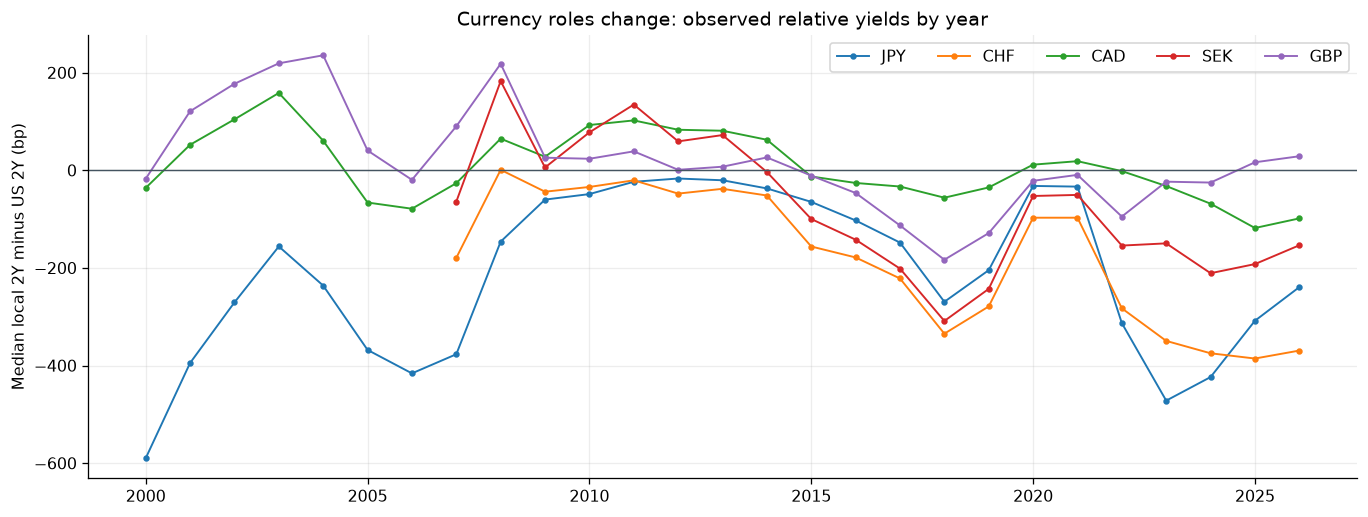

In [13]:
native = fx.read_native_features_from_raw()
known = fx.rebuild_economic_known(native, prices.date)
known_checks = fx.verify_known_features(known)
assert known_checks['pass'].all(), known_checks.to_string(index=False)
attributes = fx.currency_attributes(known)
fig, ax = plt.subplots(figsize=(12, 4.6))
for pair in ['JPY', 'CHF', 'CAD', 'SEK', 'GBP']:
    observations = attributes[attributes.pair.eq(pair)]
    ax.plot(observations.year, observations.median_known_spread_bp, label=pair, marker='.', lw=1.2)
ax.axhline(0, color='#445460', lw=.9)
ax.set_ylabel('Median local 2Y minus US 2Y (bp)')
ax.set_title('Currency roles change: observed relative yields by year')
ax.legend(ncol=5)
plt.tight_layout()
plt.savefig(FIGURES / '05_time_varying_rate_roles.png')
plt.show()

## 7. Daily VIX and economic information timing

VIX is an equity-option volatility index, not a direct FX panic probability. The earlier diagnostic distinguishes low (<20), medium (20-30) and high (>=30) levels, and falling/flat/rising five-observation changes using +/-3 points. A rising high-VIX state is different from a high but falling VIX recovery.

Feature construction separates **E**, contemporaneous end-date description; **K**, observations strictly before the signal date and no more than seven calendar days old; and **A**, K shifted to the interval when the original position earns its return. Final entry filters use K at the original technical signal date. They never use an E observation from the eventual entry/exit outcome.

Native 5- and 20-step changes are computed on each series' nonmissing observations before alignment. Five steps are limited to 12 calendar days; twenty steps to 45 days. Missing inputs remain unknown. The original workbook has no full publication/vintage history, so this is a conservative research alignment, not a strict real-time data certification.

,check,expected_rows,compared_rows,max_abs_error,mismatch_count,absolute_tolerance,pass,reference_source
0,known economic inputs: exact key coverage,62010,62010,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
1,known economic inputs: K_vix_obs_date,62010,62010,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
2,known economic inputs: K_vix,62010,62010,0.000000e+00,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
3,known economic inputs: K_vix_d5,62010,62010,3.552714e-15,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
4,known economic inputs: K_dxy_obs_date,62010,62010,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
5,known economic inputs: K_dxy_d20_pct,62010,62010,1.776357e-15,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
6,known economic inputs: K_brent_obs_date,62010,62010,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
7,known economic inputs: K_brent_d20_pct,62010,62010,7.105427e-15,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
8,known economic inputs: K_copper_obs_date,62010,62010,NaN,0,NaN,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz
9,known economic inputs: K_copper_d20_pct,62010,62010,7.105427e-15,0,1.000000e-07,True,C:\Users\pengb\Desktop\Cornell\vanguard\Technical indicator analysis\FX_Research_Datasets\data\clean\economic_known_inputs_rebuilt.csv.gz


,date,K_vix_obs_date,K_vix,K_vix_d5,K_dxy_obs_date,K_dxy_d20_pct,K_brent_obs_date,K_brent_d20_pct,K_copper_obs_date,K_copper_d20_pct,K_rate_obs_date,K_spread_bp,K_spread_d20_bp,pair
48222,2026-05-20,2026-05-19,18.06,0.07,2026-05-19,0.948229,2026-05-19,12.997563,2026-05-19,1.017914,2026-05-19,-108.4,-11.7,CAD
48223,2026-05-21,2026-05-20,17.44,-0.43,2026-05-20,0.509179,2026-05-20,3.051712,2026-05-20,3.280279,2026-05-20,-112.2,-14.9,CAD
48224,2026-05-22,2026-05-21,16.76,-0.50,2026-05-21,0.493065,2026-05-21,-2.369849,2026-05-21,0.610654,2026-05-21,-117.3,-18.0,CAD
48225,2026-05-25,2026-05-22,16.70,-1.73,2026-05-22,0.716511,2026-05-22,-1.699421,2026-05-22,2.361908,2026-05-22,-121.1,-25.0,CAD
48226,2026-05-26,2026-05-25,16.59,-1.23,2026-05-25,0.754345,2026-05-25,-11.170655,2026-05-22,2.361908,2026-05-22,-121.1,-25.0,CAD
48227,2026-05-27,2026-05-26,17.01,-1.05,2026-05-26,0.536294,2026-05-26,-10.497933,2026-05-26,2.407221,2026-05-26,-119.8,-23.5,CAD
48228,2026-05-28,2026-05-27,16.29,-1.15,2026-05-27,0.247572,2026-05-27,-20.113530,2026-05-27,2.480431,2026-05-27,-117.3,-21.1,CAD
48229,2026-05-29,2026-05-28,15.74,-1.02,2026-05-28,0.983112,2026-05-28,-17.805456,2026-05-28,5.444085,2026-05-28,-118.2,-26.7,CAD


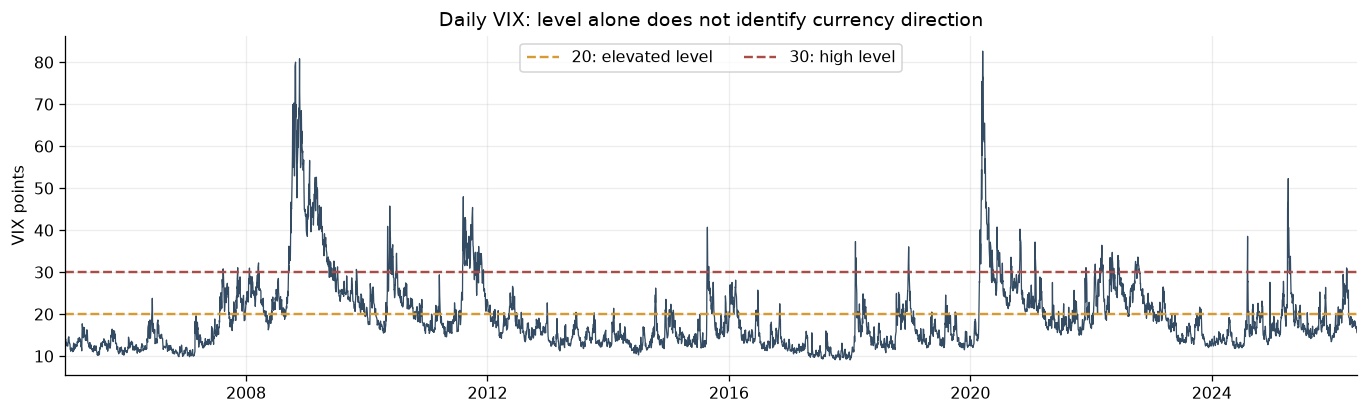

In [14]:
known_checks=fx.verify_known_features(known)
display(known_checks)
known.to_csv(OUT/'economic_known_inputs_rebuilt.csv.gz',index=False)
display(known[known.pair.eq(PAIR)].tail(8))
vix=native['5_Equities'].VIX.dropna()
fig,ax=plt.subplots(figsize=(12,3.7));ax.plot(vix.index,vix,color='#344c63',lw=.8)
ax.axhline(20,color='#d69b35',ls='--',label='20: elevated level');ax.axhline(30,color='#a84d48',ls='--',label='30: high level')
ax.set_xlim(pd.Timestamp('2005-01-01'),pd.Timestamp('2026-05-29'));ax.set_ylabel('VIX points')
ax.set_title('Daily VIX: level alone does not identify currency direction');ax.legend(ncol=2)
plt.tight_layout();plt.savefig(FIGURES/'06_vix_history.png');plt.show()

In [15]:
conditional = fx.conditional_daily(known, baseline_runs, price_dates)
conditional.to_csv(OUT / 'conditional_daily_vix_states.csv', index=False)
selected_states = conditional[conditional.pair.eq(PAIR) & conditional.strategy.isin(fx.CORE_RULES)]
display(selected_states[['strategy', 'state', 'active_days', 'years_covered', 'active_years_covered', 'mean_return_bp_per_active_day', 'original_account_pnl_usd', 'max_abs_day_share_pct']])
print('A clock: decision-known inputs shifted to the earned-return interval; state years and active years are shown separately.')

A clock: decision-known inputs shifted to the earned-return interval; state years and active years are shown separately.


,strategy,state,active_days,years_covered,active_years_covered,mean_return_bp_per_active_day,original_account_pnl_usd,max_abs_day_share_pct
1089,RSI_MR_14,L_F,797,22,20,-2.133425,-17073.425574,0.706411
1090,RSI_MR_14,L_U,41,19,11,2.320803,863.129618,7.213470
1091,RSI_MR_14,L_D,74,22,14,-3.942277,-2960.884926,5.024057
1092,RSI_MR_14,M_U,66,20,14,-3.937691,-2234.164570,7.835174
1093,RSI_MR_14,M_F,118,18,14,14.314897,15723.400307,4.169908
1094,RSI_MR_14,H_U,54,13,9,-3.946477,-1848.959231,5.575802
1095,RSI_MR_14,M_D,29,17,9,5.867104,1175.284462,16.125632
1096,RSI_MR_14,H_F,40,8,7,-19.748765,-7876.758173,10.849243
1097,RSI_MR_14,H_D,29,8,7,26.281295,7220.432632,14.063831
1143,MA_20_60,L_F,3307,22,22,0.288836,7740.107257,0.197660


### 7.1 Earlier VIX-only filters: retained as a useful failed/successful comparison

V5 tested two mean-reversion rules in all nine currencies. Entry-only rejects the rising high-VIX state (VIX >=30 and a five-observation increase of at least 3 points). Entry-plus-exit monitors the same state after entry and exits at the next close when triggered. These are deliberately distinct from the later V8 signed-yield risk filter, whose VIX threshold is 20.

A risk filter can avoid a loss yet also miss the strongest rebound. Both the full metric table and blocked-trade records are retained. We do not equate fewer trades with better trades.

In [16]:
vix_result = fx.run_vix_variants(prices, known, baseline_runs, price_dates, baseline_trades)
vix_checks = fx.verify_vix_variants(vix_result)
assert vix_checks['pass'].all(), vix_checks.loc[~vix_checks['pass']].to_string(index=False)
vix_variants = vix_result['metrics']
display(vix_variants[['pair', 'base_strategy', 'variant', 'blocked_base_trades', 'early_risk_exits', 'baseline_return_pct', 'total_return_pct', 'return_difference_pp', 'max_drawdown_pct']])
vix_variants.to_csv(OUT / 'v5_account_metrics.csv', index=False)
vix_result['trades'].to_csv(OUT / 'v5_trade_ledger.csv.gz', index=False)
vix_result['episode_decisions'].to_csv(OUT / 'v5_episode_decisions.csv.gz', index=False)
vix_checks.to_csv(OUT / 'v5_reconciliation.csv', index=False)

,pair,base_strategy,variant,blocked_base_trades,early_risk_exits,baseline_return_pct,total_return_pct,return_difference_pp,max_drawdown_pct
0,EUR,BB_MR_20,ENTRY_ONLY,8,0,4.332895,4.316705,-0.016189,-23.397805
1,EUR,BB_MR_20,RISK_EXIT,8,21,4.332895,9.937751,5.604856,-20.071103
2,EUR,RSI_MR_14,ENTRY_ONLY,6,0,-8.725626,-7.309901,1.415725,-19.141783
3,EUR,RSI_MR_14,RISK_EXIT,6,9,-8.725626,-8.718778,0.006848,-20.556322
4,GBP,BB_MR_20,ENTRY_ONLY,11,0,37.666622,33.289363,-4.377258,-16.188835
5,GBP,BB_MR_20,RISK_EXIT,11,22,37.666622,27.064228,-10.602394,-15.571052
6,GBP,RSI_MR_14,ENTRY_ONLY,3,0,15.792318,29.954698,14.162380,-13.544214
7,GBP,RSI_MR_14,RISK_EXIT,3,11,15.792318,13.482070,-2.310249,-14.061624
8,AUD,BB_MR_20,ENTRY_ONLY,5,0,35.705619,38.446238,2.740619,-25.862971
9,AUD,BB_MR_20,RISK_EXIT,5,22,35.705619,31.951099,-3.754520,-27.706127


## 8. Trade quality: win rate, payoff and opportunity cost

The unit is a **completed nonzero-position episode**, not a daily return. Open positions are reported separately. A flat completed trade stays in the win-rate denominator; tiny numerical returns use the frozen tolerance.

$$p=\frac{N_{win}}{N_{closed}},\qquad b=\frac{\overline{R}_{win}}{|\overline{R}_{loss}|},\qquad E[R]=p\overline{R}_{win}-(1-p)|\overline{R}_{loss}|$$

The expectancy identity above assumes no flat trades; the implementation calculates the direct mean and keeps flats explicitly. The no-flat break-even win rate is $1/(1+b)$. A payoff ratio below one is not automatically unprofitable if the win rate is sufficiently high. Conversely, increasing win rate by cutting profitable trends early can reduce PnL.

Entry cohorts answer which entries worked; period PnL answers when profits occurred. A trade crossing a year boundary must not be assigned wholesale to its entry year when explaining calendar-year PnL. All comparisons below use the appropriate denominator.

,strategy,eligible_closed_n,win_n,loss_n,flat_n,win_rate,avg_win_return,avg_loss_abs_return,payoff_ratio,expectancy_return,median_holding_observations
138,RSI_MR_7,240,158.0,82.0,0.0,0.658333,0.007993,0.010972,0.728511,0.001513,4.0
139,RSI_MR_14,66,44.0,22.0,0.0,0.666667,0.009629,0.021969,0.438293,-0.000904,13.0
140,RSI_MR_20,26,17.0,9.0,0.0,0.653846,0.015300,0.025819,0.592592,0.001067,26.0
141,RSI_MOM_7,812,349.0,457.0,6.0,0.429803,0.007041,0.006058,1.162348,-0.000383,2.0
142,RSI_MOM_14,476,204.0,271.0,1.0,0.428571,0.007411,0.006144,1.206056,-0.000322,2.0
143,RSI_MOM_20,332,143.0,188.0,1.0,0.430723,0.008113,0.006328,1.282149,-0.000089,2.0
144,MA_10_30,228,77.0,151.0,0.0,0.337719,0.020901,0.011761,1.777090,-0.000731,20.5
145,MA_20_60,111,39.0,72.0,0.0,0.351351,0.033627,0.016580,2.028121,0.001060,39.0
146,BB_MR_10,223,138.0,85.0,0.0,0.618834,0.009081,0.011257,0.806707,0.001329,7.0
147,BB_MR_20,185,120.0,65.0,0.0,0.648649,0.010232,0.017557,0.582767,0.000468,12.0


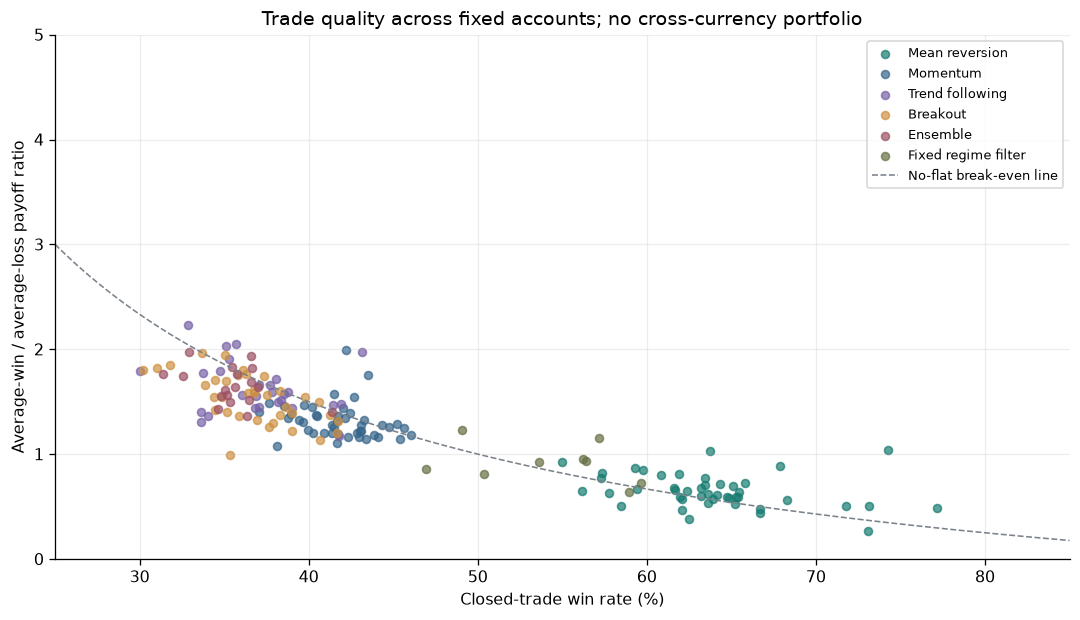

In [17]:
quality_reference=pd.read_csv(DATA / 'clean/fixed_baseline_metrics_rebuilt.csv')
qcheck=tech.merge(quality_reference,on=['pair','strategy'],suffixes=('_new','_reference'))
for column in ['eligible_closed_n','win_rate','payoff_ratio','account_pnl_usd']:
    assert np.allclose(qcheck[column+'_new'],qcheck[column+'_reference'],atol=1e-7,rtol=1e-9,equal_nan=True),column
display(tech[tech.pair.eq(PAIR)][['strategy','eligible_closed_n','win_n','loss_n','flat_n','win_rate',
 'avg_win_return','avg_loss_abs_return','payoff_ratio','expectancy_return','median_holding_observations']])
fig,ax=plt.subplots(figsize=(9.5,5.5))
for name,color in [('Mean reversion','#167b70'),('Momentum','#36658a'),('Trend following','#7761a6'),('Breakout','#ce9142'),('Ensemble','#9b5063'),('Fixed regime filter','#657044')]:
    z=tech[tech.hypothesis.eq(name)];ax.scatter(100*z.win_rate,z.payoff_ratio,label=name,c=color,s=25,alpha=.7)
x=np.linspace(25,85,180);ax.plot(x,100/x-1,color='#7b828b',ls='--',lw=1,label='No-flat break-even line')
ax.set_xlim(25,85);ax.set_ylim(0,5);ax.set_xlabel('Closed-trade win rate (%)');ax.set_ylabel('Average-win / average-loss payoff ratio')
ax.set_title('Trade quality across fixed accounts; no cross-currency portfolio');ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(FIGURES/'07_win_rate_payoff.png');plt.show()

## 9. Economic filters: hypotheses fixed before candidate results

Let $q=+1$ for long foreign/short USD and $q=-1$ for short foreign/long USD. Let $d$ be local two-year government yield minus US two-year yield in basis points. Germany proxies the EUR yield; this is neither actual carry nor an identified monetary-policy shock.

| Version | Reject the original technical entry when... |
|---|---|
| BASE | Never; original technical entry/exit. |
| RATE_CHANGE_CONFLICT (V7) | $q\Delta_{20}d\le -10$ bp. |
| DUAL_RATE_CONFLICT (V7) | $q\Delta_{20}d\le -10$ bp and $qd\le-50$ bp. |
| POLICY_USD | $q\Delta_{20}d\le -10$ bp and $q\Delta_{20}DXY\ge1\%$. |
| RISK_YIELD | VIX >=20, five-observation VIX change >=3 points, and $qd\ge50$ bp. |
| COMMODITY_USD | For AUD use copper; for CAD/NOK use Brent. Reject if $q\Delta_{20}C<0$ and $q\Delta_{20}DXY\ge1\%$. Other currencies: not applicable. |
| ECO_COMPOSITE | Any confirmed POLICY_USD, RISK_YIELD or COMMODITY_USD rejection. The OR was fixed before results. |
| RISK_YIELD_EXIT | Entry uses RISK_YIELD. During an accepted episode, monitor the same condition; exit at the next FX close on the first trigger. |

All required inputs must be finite. An unknown component preserves the original entry unless another OR component confirms rejection. A rejected episode stays flat until the next original technical episode; no opportunistic delayed re-entry is allowed. Accepted entry-only trades keep the original technical exit. Early risk exits retain the return up to the execution close and lock the remainder of that original episode.

DXY contains several of the currencies being studied: it is a common-dollar confirmation variable, not an independent causal instrument. Commodity proxies are incomplete; no dairy proxy is invented for NZD. The economic interpretation is a hypothesis supported by institutional research, not proof that a threshold is optimal. See [Federal Reserve, relative policy expectations](https://www.federalreserve.gov/econres/notes/ifdp-notes/the-sensitivity-of-the-us-dollar-exchange-rate-to-changes-in-monetary-policy-expectations-20170922.htm) and [ICE, USDX composition](https://www.ice.com/forex/usdx).

In [18]:
predicates = {
    'RATE_CHANGE_CONFLICT': 'direction * 20-observation spread change <= -10 bp',
    'DUAL_RATE_CONFLICT': 'rate-change conflict AND direction * spread <= -50 bp',
    'POLICY_USD': 'rate-change conflict AND direction * DXY 20-observation change >= 1%',
    'RISK_YIELD': 'VIX >= 20 AND VIX 5-observation change >= 3 AND direction * spread >= 50 bp',
    'COMMODITY_USD': 'AUD copper / CAD,NOK Brent: direction * commodity change < 0 AND direction * DXY change >= 1%',
    'ECO_COMPOSITE': 'Confirmed POLICY_USD OR RISK_YIELD OR COMMODITY_USD rejection',
    'RISK_YIELD_EXIT': 'RISK_YIELD entry gate plus next-close exit on the first accepted-episode risk trigger',
}
display(pd.DataFrame([{'version': name, 'predicate': predicate} for name, predicate in predicates.items()]))
print('Reconstructed implementation; original protocol files and frozen engine are unavailable.')
filtered_metrics, filter_checks, filter_tables = fx.reproduce_v8(
    OUT / 'v8', prices=prices, known=known,
    baseline=(baseline_metrics, baseline_trades, baseline_runs, price_dates, indicators))
display(filter_checks)
assert len(filtered_metrics) == 288
assert filter_checks['pass'].all(), filter_checks.to_string(index=False)

Reconstructed implementation; original protocol files and frozen engine are unavailable.


,version,predicate
0,RATE_CHANGE_CONFLICT,direction * 20-observation spread change <= -10 bp
1,DUAL_RATE_CONFLICT,rate-change conflict AND direction * spread <= -50 bp
2,POLICY_USD,rate-change conflict AND direction * DXY 20-observation change >= 1%
3,RISK_YIELD,VIX >= 20 AND VIX 5-observation change >= 3 AND direction * spread >= 50 bp
4,COMMODITY_USD,"AUD copper / CAD,NOK Brent: direction * commodity change < 0 AND direction * DXY change >= 1%"
5,ECO_COMPOSITE,Confirmed POLICY_USD OR RISK_YIELD OR COMMODITY_USD rejection
6,RISK_YIELD_EXIT,RISK_YIELD entry gate plus next-close exit on the first accepted-episode risk trigger


,check,expected_rows,compared_rows,max_abs_error,mismatch_count,absolute_tolerance,pass,reference_source
0,filter exact account coverage,288,288,NaN,0,NaN,True,Explorer filter schema
1,filter total_return_pct: AUD BB_MR_20 BASE,1,1,0.000000e+00,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|BASE
2,filter max_drawdown_pct: AUD BB_MR_20 BASE,1,1,0.000000e+00,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|BASE
3,filter eligible_closed_n: AUD BB_MR_20 BASE,1,1,0.000000e+00,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|BASE
4,filter win_rate: AUD BB_MR_20 BASE,1,1,0.000000e+00,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|BASE
5,filter payoff_ratio: AUD BB_MR_20 BASE,1,1,1.523226e-13,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|BASE
6,filter daily: AUD BB_MR_20 BASE,5585,5585,5.476904e-07,0,1.100000e-06,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|BASE
7,filter total_return_pct: AUD BB_MR_20 COMMODITY_USD,1,1,8.098056e-11,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|COMMODITY_USD
8,filter max_drawdown_pct: AUD BB_MR_20 COMMODITY_USD,1,1,1.900702e-11,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|COMMODITY_USD
9,filter eligible_closed_n: AUD BB_MR_20 COMMODITY_USD,1,1,0.000000e+00,0,1.000000e-07,True,FX_PnL_Explorer.html#main|AUD|BB_MR_20|COMMODITY_USD


### 9.1 Iteration record and the full denominator

Round 1 inspected three independent economic entry conflicts. Round 2 inspected the pre-fixed OR. Development-history diagnosis motivated a separate risk-exit addendum; the addendum was frozen before opening its later candidate results. All eight final variants were retained for full review, including failures.

This order constrains the documented iteration, but it does not restore untouched OOS because underlying prices and earlier analyses had already been observed. Commodity-filter breadth must use **12 applicable accounts**, not 36.

The practical historical screen requires win rate +2 percentage points, payoff ratio +10% relative, cumulative return +5 points, maximum-drawdown deterioration no more than 2 points, at least 50% of closed trades retained, and at least 30 closed trades. Later-history quality/PnL and calendar consistency checks are additional conditions. Passing is a historical screening result, not statistical significance or future-profit proof.

In [19]:
iterations = fx.breadth_summary(filtered_metrics)
display(iterations)
acceptance = pd.read_csv(filter_tables / 'account_acceptance.csv')
passing = acceptance[acceptance.final_practical_pass]
print('Recomputed screen using explicit reconstructed conditions; the original frozen protocol file is unavailable.')
print(json.dumps(fx.SCREEN_SPECIFICATION, indent=2))
display(passing[['pair', 'base_strategy', 'variant', 'win_rate_difference_pp', 'payoff_ratio_relative_improvement', 'return_difference_pp', 'retained_closed_fraction', 'positive_calendar_blocks', 'final_practical_pass']])
archived_passing = fx.saved_notebook_table(32, 1)
screen_keys = ['pair', 'base_strategy', 'variant']
screen_matches_archived = set(passing[screen_keys].itertuples(index=False, name=None)) == set(archived_passing[screen_keys].itertuples(index=False, name=None))
print('Reconstructed passing identities match saved historical rows:', screen_matches_archived)

Recomputed screen using explicit reconstructed conditions; the original frozen protocol file is unavailable.
{
  "win_rate_improvement_percentage_points": 2.0,
  "payoff_ratio_relative_improvement": 0.1,
  "return_improvement_percentage_points": 5.0,
  "maximum_drawdown_deterioration_percentage_points": 2.0,
  "minimum_retained_closed_fraction": 0.5,
  "minimum_closed_trades": 30,
  "minimum_positive_calendar_blocks": 3,
  "review_condition": "Win rate, payoff ratio and return must each be no worse than BASE in 2015 onward.",
  "source": "Delivered notebook cell 31; review and calendar conditions reconstructed explicitly.",
  "original_frozen_protocol_available": false,
  "new_untouched_out_of_sample": false
}
Reconstructed passing identities match saved historical rows: True


,variant,accounts,win_rate_up,payoff_up,both_up,both_and_pnl_up,pnl_up,dd_not_worse,universal_breadth_target_met
0,RATE_CHANGE_CONFLICT,36,19,22,13,13,21,28,False
1,DUAL_RATE_CONFLICT,36,18,20,11,11,23,22,False
2,POLICY_USD,36,16,17,7,6,20,28,False
3,RISK_YIELD,36,23,20,13,13,25,26,False
4,ECO_COMPOSITE,36,23,24,15,14,27,32,False
5,RISK_YIELD_EXIT,36,27,20,17,17,21,28,False
6,COMMODITY_USD,12,9,11,8,8,11,10,False


,pair,base_strategy,variant,win_rate_difference_pp,payoff_ratio_relative_improvement,return_difference_pp,retained_closed_fraction,positive_calendar_blocks,final_practical_pass
59,GBP,RSI_MR_14,POLICY_USD,5.398111,0.223328,13.986467,0.730769,3,True
62,GBP,RSI_MR_14,ECO_COMPOSITE,5.398111,0.223328,13.986467,0.730769,3,True
213,CAD,BB_MR_20,COMMODITY_USD,2.482074,0.347933,37.251702,0.794595,3,True
214,CAD,BB_MR_20,ECO_COMPOSITE,2.511022,0.341656,34.840831,0.762162,4,True
287,SEK,RSI_MR_14,RISK_YIELD_EXIT,2.777778,0.146390,19.005177,0.958333,4,True


## 10. Final improvements, complete curves and concentration

The strongest retained historical candidate is CAD BB20 with the commodity/USD entry filter. GBP RSI14 improves but depends heavily on one crisis trade. SEK RSI14 improves mainly through entry rejection; adding the risk exit contributes only about 1.68 percentage points of full-history return beyond the entry-only version.

Improvement is evaluated jointly with missed winning trades, sample retention, period failures and concentration. The same mechanism can help one rule and hurt another, or reverse its effect over time.

,pair,base_strategy,variant,eligible_closed_n,win_rate,payoff_ratio,total_return_pct,cagr_calendar_pct,max_drawdown_pct
0,CAD,BB_MR_20,BASE,185,0.648649,0.582767,5.715812,0.259989,-28.010972
1,CAD,BB_MR_20,DUAL_RATE_CONFLICT,173,0.647399,0.557006,-0.570111,-0.026704,-28.850704
2,CAD,BB_MR_20,COMMODITY_USD,147,0.673469,0.785530,42.967514,1.683766,-12.437097
3,GBP,RSI_MR_14,BASE,78,0.717949,0.505998,15.792318,0.687297,-17.111278
4,GBP,RSI_MR_14,DUAL_RATE_CONFLICT,74,0.729730,0.491014,17.308557,0.748504,-17.111278
5,GBP,RSI_MR_14,POLICY_USD,57,0.771930,0.619001,29.778785,1.225073,-9.869055
6,SEK,RSI_MR_14,BASE,72,0.638889,0.572392,-2.270208,-0.107213,-26.168592
7,SEK,RSI_MR_14,DUAL_RATE_CONFLICT,53,0.641509,0.525652,-6.641697,-0.320523,-22.527933
8,SEK,RSI_MR_14,RISK_YIELD_EXIT,69,0.666667,0.656185,16.734970,0.725439,-19.624896


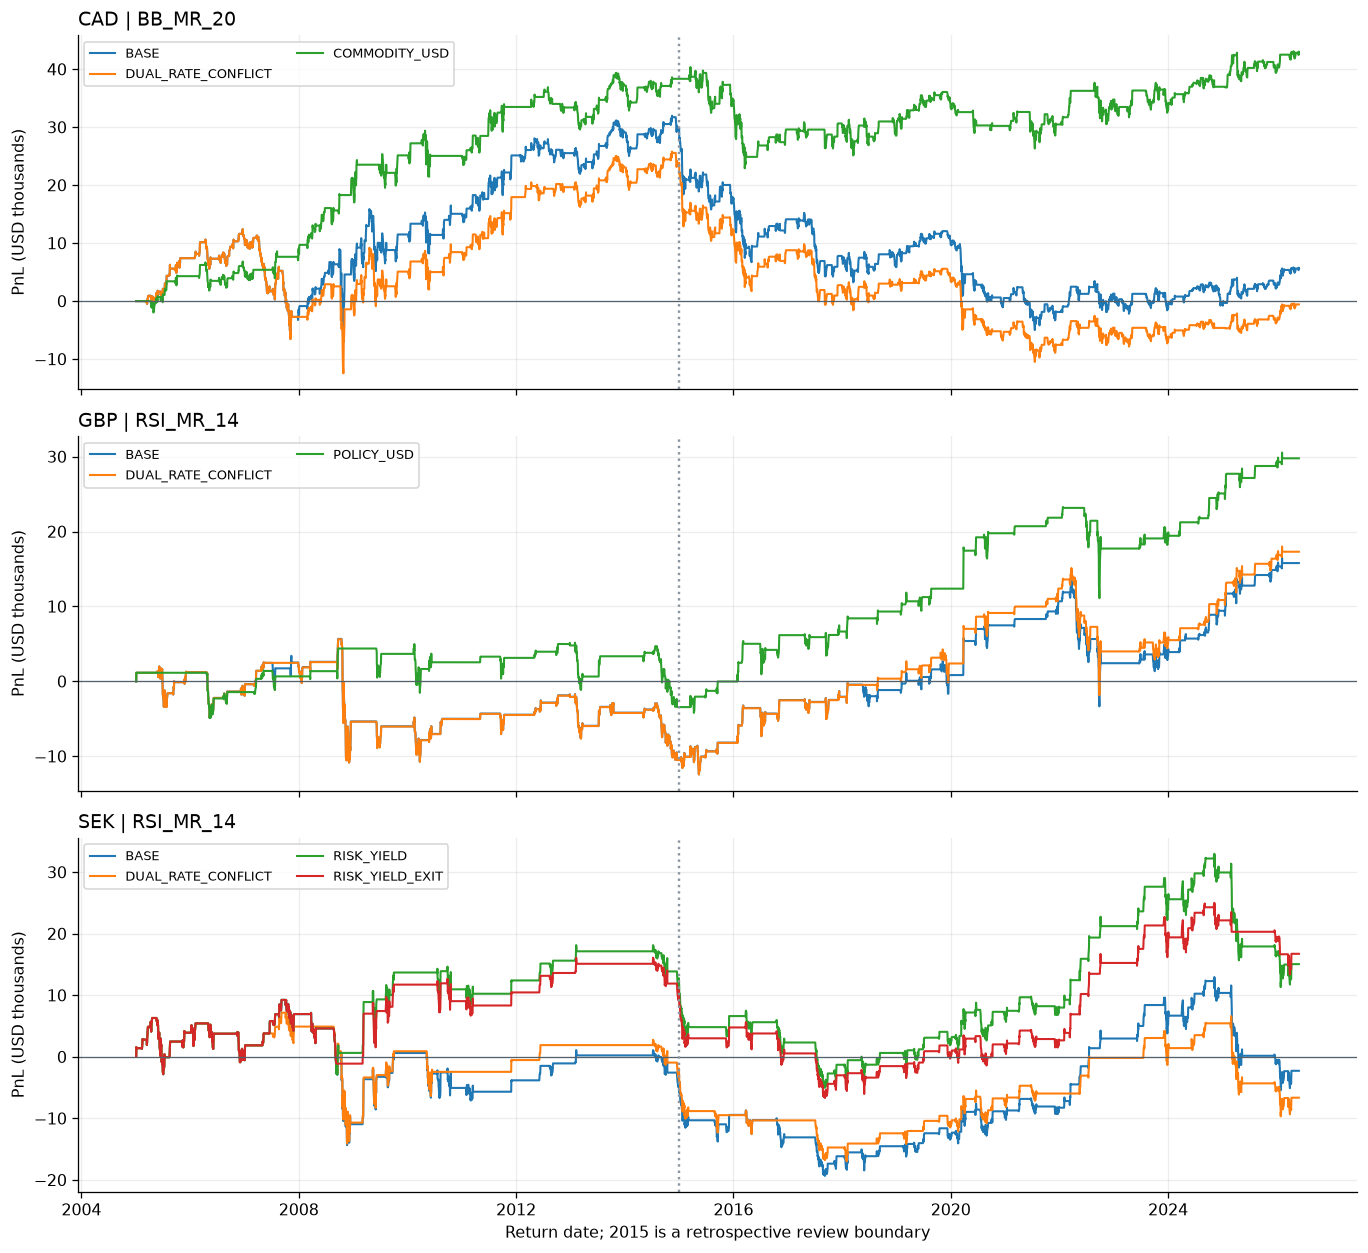

In [20]:
chosen=[('CAD','BB_MR_20','COMMODITY_USD'),('GBP','RSI_MR_14','POLICY_USD'),('SEK','RSI_MR_14','RISK_YIELD_EXIT')]
selected=[]
for pair,rule,variant in chosen:
    z=filtered_metrics[filtered_metrics.pair.eq(pair)&filtered_metrics.base_strategy.eq(rule)&filtered_metrics.variant.isin(['BASE','DUAL_RATE_CONFLICT',variant])]
    selected.append(z)
selected_metrics=pd.concat(selected,ignore_index=True)
display(selected_metrics[['pair','base_strategy','variant','eligible_closed_n','win_rate','payoff_ratio','total_return_pct','cagr_calendar_pct','max_drawdown_pct']])
# Read only the selected exact daily curves, not a resampled curve or a rounded image.
wanted={('GBP','RSI_MR_14'),('CAD','BB_MR_20'),('SEK','RSI_MR_14')}
frames=[]
cols=['pair','base_strategy','variant','date','cumulative_pnl_usd']
for chunk in pd.read_csv(filter_tables/'daily_accounts.csv.gz',usecols=cols,chunksize=150000,parse_dates=['date']):
    mask=np.array([(p,s) in wanted for p,s in zip(chunk.pair,chunk.base_strategy)])
    frames.append(chunk.loc[mask])
curves=pd.concat(frames,ignore_index=True)
fig,axes=plt.subplots(3,1,figsize=(12,11),sharex=True)
for ax,(pair,rule,variant) in zip(axes,chosen):
    variants=['BASE','DUAL_RATE_CONFLICT',variant]
    if pair=='SEK':variants.insert(2,'RISK_YIELD')
    for v in variants:
        g=curves[curves.pair.eq(pair)&curves.base_strategy.eq(rule)&curves.variant.eq(v)].sort_values('date')
        ax.plot(g.date,g.cumulative_pnl_usd/1000,label=v,lw=1.3)
    ax.axhline(0,color='#54616a',lw=.8);ax.axvline(pd.Timestamp('2015-01-01'),color='#8b959f',ls=':')
    ax.set_title(f'{pair} | {rule}',loc='left');ax.set_ylabel('PnL (USD thousands)');ax.legend(ncol=2,fontsize=8)
axes[-1].set_xlabel('Return date; 2015 is a retrospective review boundary')
plt.tight_layout();plt.savefig(FIGURES/'08_selected_filter_pnl.png');plt.show()

In [21]:
concentration = pd.read_csv(filter_tables / 'episode_concentration.csv')
focus = pd.DataFrame(chosen, columns=['pair', 'base_strategy', 'variant']).merge(concentration, on=['pair', 'base_strategy', 'variant'])
display(focus[['pair', 'base_strategy', 'variant', 'changed_episodes', 'beneficial_n', 'harmful_n', 'numerically_flat_n', 'largest_positive_share_of_gross_positive', 'top3_positive_share_of_gross_positive', 'return_without_largest_positive_effect_pct']])
concentration_reference = fx.saved_notebook_table(35, 0)
concentration_check = focus.merge(concentration_reference, on=['pair', 'base_strategy', 'variant'], suffixes=('_new', '_reference'), validate='one_to_one')
for measure in ['changed_episodes', 'largest_positive_share_of_gross_positive', 'top3_positive_share_of_gross_positive', 'return_without_largest_positive_effect_pct']:
    assert np.allclose(concentration_check[measure + '_new'], concentration_check[measure + '_reference'], atol=5.1e-7, rtol=1e-9), measure
calendar = pd.read_csv(filter_tables / 'calendar_period_pnl.csv')
comparison_keys = chosen + [('AUD', 'BB_MR_20', 'COMMODITY_USD'), ('NOK', 'RSI_MR_14', 'COMMODITY_USD')]
period_focus = pd.DataFrame(comparison_keys, columns=['pair', 'base_strategy', 'variant']).merge(calendar, on=['pair', 'base_strategy', 'variant'])
display(period_focus.pivot(index=['pair', 'base_strategy', 'variant'], columns='period', values='return_difference_pp'))

,pair,base_strategy,variant,changed_episodes,beneficial_n,harmful_n,numerically_flat_n,largest_positive_share_of_gross_positive,top3_positive_share_of_gross_positive,return_without_largest_positive_effect_pct
0,CAD,BB_MR_20,COMMODITY_USD,38,17,21,0,0.154889,0.447524,31.088454
1,GBP,RSI_MR_14,POLICY_USD,21,8,12,1,0.474378,0.778508,16.245085
2,SEK,RSI_MR_14,RISK_YIELD_EXIT,11,5,6,0,0.498799,0.970116,3.305488


,,period,2005-2009,2010-2014,2015-2019,2020-2024,2025-2026YTD
pair,base_strategy,variant,,,,,
AUD,BB_MR_20,COMMODITY_USD,24.827885,6.922006,-0.231411,-3.354322,-8.564163
CAD,BB_MR_20,COMMODITY_USD,13.643728,-5.810619,11.739800,11.976680,-1.705512
GBP,RSI_MR_14,POLICY_USD,9.669359,-2.094640,3.737973,2.799226,-2.069900
NOK,RSI_MR_14,COMMODITY_USD,13.481619,17.504119,-0.726198,-3.338457,-1.735091
SEK,RSI_MR_14,RISK_YIELD_EXIT,11.110448,3.259092,0.297223,-5.016837,7.014139


### Economic interpretation, with both successful and failed trades

**CAD, 2014-2015.** A BB20 long entered on 2014-12-09 lost 8.18% before the original exit. Entry-time known inputs showed Brent down 17.17% over 20 native observations, DXY up 1.93%, and VIX only 11.82. The commodity/USD filter rejected it without needing a panic label. Canada's January 2015 rate cut explicitly cited the oil-price shock, supporting a persistent repricing interpretation during the holding period. That announcement occurred after entry and was not an input to the signal. [Bank of Canada statement](https://www.bankofcanada.ca/2015/01/fad-press-release-2015-01-21/).

The filter also deleted profitable CAD longs in 2010 and 2011. A past commodity decline may represent a continuing shock or an adjustment already reflected in price. It does not distinguish the two perfectly. Reversing the largest helpful rule change leaves CAD's return at about 31.09% versus the 5.72% baseline; the improvement is not wholly concentrated in one transaction.

**GBP, 2008.** Avoiding one long that lost about 10.43% explains much of the gain. Reversing the single largest helpful modification reduces the improved account from 29.78% to about 16.25%, versus 15.79% originally. The evidence is therefore weaker than the headline win-rate gain alone suggests. A March 2022 rejected entry cannot be explained by the later September mini-budget; chronology matters.

**SEK, 2025 and 2020.** In February 2025, the strategy was short SEK/long USD; USD was the higher-yield side. A risk signal on February 28, using February 27 information, led to a March 3 exit and reduced a roughly 9.25% loss to 1.52%. Subsequent Riksbank discussion describes US-asset outflows, European equity flows and relative-growth channels. This is ex-post background, not a forecast input. In 2020, a similar risk exit missed a profitable USD move: a 1.93% winning episode became approximately 0.01%. Dollar-funding demand can support USD during stress. [Riksbank March 2025 minutes](https://www.riksbank.se/globalassets/media/dagordningar--protokoll/protokoll/penningpolitiskt/engelska/2025/minutes-of-the-monetary-policy-meeting-on-19-march-2025.pdf); [BIS 2020](https://www.bis.org/publications/aer-2020/monetary-lifeline-central-banks-crisis-response).

**JPY, 2008 versus 2024.** The same BB risk-exit rule reduced a 2008 short's loss from about 10.86% to 0.32%, but worsened a 2024 short from about 6.86% to 8.40%. In the latter case the delayed exit missed part of the recovery. BIS describes how macro news and leveraged unwinds amplified August 2024 turbulence, followed by relatively quick stabilization. That is consistent with the observed path, not proof that stabilization was predictable. [BIS Bulletin 90](https://www.bis.org/publications/bulletin-90-market-turbulence-and-carry-trade-unwind-august-2024).

These comparisons support a time x currency x trade-direction analysis. They do not support permanently designating CAD as mean reverting, or JPY/USD as always benefiting from a fixed risk response.

In [22]:
case_evidence = pd.read_csv(filter_tables / 'case_evidence.csv.gz')
case_columns = ['pair', 'base_strategy', 'variant', 'original_episode', 'entry_date', 'original_exit_date', 'accepted', 'early_risk_exit', 'base_trade_return_pct', 'effective_trade_return_pct', 'log_wealth_effect']
selected_cases = pd.DataFrame(chosen, columns=['pair', 'base_strategy', 'variant']).merge(case_evidence, on=['pair', 'base_strategy', 'variant'])
display(selected_cases[selected_cases.changed].sort_values('log_wealth_effect', ascending=False)[case_columns].head(20))
print('Complete entry and risk-signal evidence for every episode is exported, including rejected winners and harmful exits.')

Complete entry and risk-signal evidence for every episode is exported, including rejected winners and harmful exits.


,pair,base_strategy,variant,original_episode,entry_date,original_exit_date,accepted,early_risk_exit,base_trade_return_pct,effective_trade_return_pct,log_wealth_effect
281,SEK,RSI_MR_14,RISK_YIELD_EXIT,17,2008-10-09,2008-12-12,False,False,-11.504249,0.000000,0.122216
200,GBP,RSI_MR_14,POLICY_USD,14,2008-10-14,2008-12-16,False,False,-10.428284,0.000000,0.110131
18,CAD,BB_MR_20,COMMODITY_USD,18,2007-03-22,2007-06-19,False,False,-8.308922,0.000000,0.086745
84,CAD,BB_MR_20,COMMODITY_USD,84,2014-12-09,2015-02-16,False,False,-8.182256,0.000000,0.085365
333,SEK,RSI_MR_14,RISK_YIELD_EXIT,69,2025-02-24,2025-05-13,True,True,-9.250091,-1.516318,0.081783
22,CAD,BB_MR_20,COMMODITY_USD,22,2007-09-13,2007-11-13,False,False,-7.552084,0.000000,0.078525
104,CAD,BB_MR_20,COMMODITY_USD,104,2017-05-23,2017-08-07,False,False,-6.291008,0.000000,0.064976
38,CAD,BB_MR_20,COMMODITY_USD,38,2009-05-01,2009-06-15,False,False,-4.753633,0.000000,0.048703
244,GBP,RSI_MR_14,POLICY_USD,58,2022-03-10,2022-05-24,False,False,-4.233532,0.000000,0.043258
127,CAD,BB_MR_20,COMMODITY_USD,127,2020-02-28,2020-04-07,False,False,-4.187808,0.000000,0.042780


## 11. What the evidence establishes, and the OOS boundary

The final full-history comparison finds improvements in particular accounts. The three-mechanism OR improves both win rate and payoff in 15/36 accounts and PnL in 27/36. Risk entry-plus-exit improves both quality measures in 17/36 and PnL in 21/36. The commodity filter improves both in 8/12 applicable accounts and PnL in 11/12. No universal version passes every predeclared breadth condition.

The 2015-2026 review history is not new OOS. In that later history, CAD BB commodity filtering changes return from -18.52% to +3.34%; GBP RSI policy/USD filtering from +29.34% to +34.39%; SEK RSI risk entry/exit from +2.14% to +6.23%. These are useful historical comparisons, not untouched confirmation.

Absolute returns remain modest: the selected CAD, GBP and SEK variants have full-history annualized returns of approximately 1.68%, 1.23% and 0.73% before costs and without carry. Better historical trade quality is not yet a high-return deployable strategy.

The work stops at consolidation. The preserved candidates and failed versions define what a future test must evaluate unchanged. Further historical tuning would create another research version, not improve the evidential status of the existing holdout. Extra one/two-quote delay and stricter stale-data sensitivity were suggested in earlier audits but were not executed in V8; they are not presented as completed tests.

In [23]:
review=pd.read_csv(filter_tables/'phase_metrics.csv')
review=review[review.phase.eq('RETROSPECTIVE_REVIEW')]
rows=[]
for pair,rule,variant in chosen:
    rows.append(review[review.pair.eq(pair)&review.base_strategy.eq(rule)&review.variant.isin(['BASE',variant])])
display(pd.concat(rows)[['pair','base_strategy','variant','eligible_closed_n','win_rate','payoff_ratio','total_return_pct',
 'max_drawdown_pct','phase_entry_n','phase_open_or_censored_n']])
print('Research classification: previously examined historical candidate analysis; new untouched OOS pending.')

Research classification: previously examined historical candidate analysis; new untouched OOS pending.


,pair,base_strategy,variant,eligible_closed_n,win_rate,payoff_ratio,total_return_pct,max_drawdown_pct,phase_entry_n,phase_open_or_censored_n
626,CAD,BB_MR_20,BASE,100,0.600000,0.530583,-18.516629,-26.837343,101,1
641,CAD,BB_MR_20,COMMODITY_USD,86,0.639535,0.618975,3.341992,-12.437097,87,1
170,GBP,RSI_MR_14,BASE,47,0.787234,0.703930,29.336255,-14.748100,47,0
179,GBP,RSI_MR_14,POLICY_USD,36,0.861111,0.978127,34.394314,-9.869055,36,0
842,SEK,RSI_MR_14,BASE,39,0.666667,0.661340,2.143054,-16.281330,39,0
863,SEK,RSI_MR_14,RISK_YIELD_EXIT,38,0.684211,0.724178,6.232970,-15.124883,38,0


## 12. Reproducibility and files

- `src/fx_baselines.py`: raw Excel reading, technical rules, four execution modes, delayed execution, trade accounting and calendar summaries.
- `src/fx_economics.py`: native economic inputs, known-date alignment and 288 economic-filter accounts.
- `src/fx_evidence.py`: independent retained-reference checks and archived notebook evidence.
- `src/fx_legacy.py`: V3 price gates and independent H.10 replay.
- `src/fx_risk.py`: V5 VIX filters and applied-state attribution.
- `src/fx_analysis.py`: episode effects, concentration, explicit historical screen and complete case ledger.
- `src/fx_research.py`: public API and report integration.
- `run_research.py`: sequential headless execution of every code cell, saving an executed notebook separately.
- `FX_Research_Datasets/data/`: original workbooks and cleaned reference datasets, unchanged.
- `reference/notebook_saved_outputs.json`: original textual evidence and original notebook SHA-256.
- `reproduced/`: new metrics, trade ledgers, filter paths, executed notebook and validation summary.
- `notebook_figures/`: regenerated figures.

Original frozen engines, version history, rejected rolling snapshot and historical protocol files are not fabricated. All displayed numerical analyses are recomputed. The historical screen states reconstructed conditions and compares its passing identities to retained evidence; it does not recreate the missing frozen protocol. Fresh filter validation still requires new data with defensible publication timing. Institutional references remain in the PDF and preceding narrative.

In [24]:
validation_summary = {
    'implementation_status': 'reconstructed source, compared with independently retained outputs',
    'available_raw_file_hashes_verified': bool(raw_checks.loc[raw_checks.available, 'sha256_matches'].all()),
    'missing_original_raw_files': raw_checks.loc[~raw_checks.available, 'manifest_path'].tolist(),
    'original_snapshot_accounts': int(len(original_metrics)),
    'fixed_baseline_accounts': int(len(baseline_metrics)),
    'daily_baseline_rows_reconciled': int(compared_daily_rows),
    'baseline_checks_pass': bool(baseline_checks['pass'].all()),
    'economic_feature_checks_pass': bool(known_checks['pass'].all()),
    'reconstructed_filter_accounts': int(len(filtered_metrics)),
    'filter_reconciliation_checks_pass': bool(filter_checks['pass'].all()),
    'reconstructed_historical_passing_rows': int(len(passing)),
    'reconstructed_screen_matches_archived': bool(screen_matches_archived),
    'v3_accounts': int(len(v3_result['metrics'])),
    'v3_checks_pass': bool(v3_checks['pass'].all()),
    'h10_accounts': int(len(external)),
    'h10_checks_pass': bool(h10_checks['pass'].all()),
    'v5_accounts': int(len(vix_variants)),
    'v5_checks_pass': bool(vix_checks['pass'].all()),
    'new_untouched_OOS': False,
    'zero_costs': True,
    'source_sha256': fx.source_manifest(),
    'not_reconstructed': ['original source bytes and version history', 'original protocol files and freeze timestamps',
                          'rejected rolling-selection snapshot'],
}
(OUT / 'notebook_validation_summary.json').write_text(json.dumps(validation_summary, indent=2))
display(pd.DataFrame([{key: value for key, value in validation_summary.items()
                       if key not in ('source_sha256', 'not_reconstructed', 'missing_original_raw_files')}]))

,implementation_status,available_raw_file_hashes_verified,original_snapshot_accounts,fixed_baseline_accounts,daily_baseline_rows_reconciled,baseline_checks_pass,economic_feature_checks_pass,reconstructed_filter_accounts,filter_reconciliation_checks_pass,reconstructed_historical_passing_rows,reconstructed_screen_matches_archived,v3_accounts,v3_checks_pass,h10_accounts,h10_checks_pass,v5_accounts,v5_checks_pass,new_untouched_OOS,zero_costs
0,"reconstructed source, compared with independently retained outputs",True,792,207,1156095,True,True,288,True,5,True,702,True,207,True,36,True,False,True
